# Exploring Dengue-Related Symptoms, Fever Characteristics, and Exposure Factors Among Study Participants in Bangladesh

**Course:** BDS3106 — Programming for Data Science  
**Project Stage:** Mid-Term Project (Phase I — Data Audit, Validation & Exploratory Data Analysis)  
**Notebook Version:** v3  
**Author:** Student Research Team  
**Target Audience:** General Public in Bangladesh & Academic Evaluation Committee  

---

## 1. Project Overview

### 1.1 Background Context
Dengue fever is a major seasonal public health challenge in Bangladesh, primarily transmitted by infected female *Aedes aegypti* and *Aedes albopictus* mosquitoes. During outbreak periods, individuals across urban and semi-urban centers seek medical evaluation for acute fever and associated symptoms.

This project is an **exploratory data analysis (EDA)** investigating patterns among study participants with recorded dengue test results.

### 1.2 Target Audience & Communication Principles
Our target audience includes the **general public of Bangladesh** alongside university faculty and academic peers. Because health communication for the general public must be accessible, transparent, and scientifically cautious, we adhere strictly to non-causal and descriptive language principles:
- **Language we use:** *"associated with"*, *"observed more frequently"*, *"difference between groups"*, *"pattern observed in this dataset"*.
- **Language we strictly avoid:** *"causes"*, *"proves"*, *"diagnoses"*, *"clinically confirmed"* (unless explicitly substantiated by medical source records).

### 1.3 Project Boundaries: What This Project IS and IS NOT
To maintain academic integrity and ethical data science standards, we establish clear project boundaries:
- **What this project IS:** An exploratory investigation of symptom frequencies, severity ratings, vomiting episodes, fever characteristics, and environmental exposure factors among study participants.
- **What this project IS NOT:**
  1. It is **NOT** a clinical diagnostic system or medical decision-making tool.
  2. It does **NOT** establish biological or clinical causality.
  3. It does **NOT** estimate national dengue prevalence across Bangladesh (this dataset contains survey-based participant records with recorded dengue test results, not a randomized national population census).
  4. It does **NOT** provide medical advice or substitute for laboratory clinical testing.

### 1.4 Approved Population Wording (Decision 1)
During initial inspection, we identified that **2 participants recorded `fever_days = 0`**. Therefore, describing all 1,018 individuals as "febrile patients" is inaccurate.
- Throughout this study, we refer to the entire dataset cohort as **"study participants"** or **"participants with recorded dengue test results"**.
- We reserve the term **"participants with recorded fever"** specifically for subgroups where fever was actively recorded (`fever_days > 0`).

## 2. Dataset Source and Licence

To ensure academic traceability and reproducibility, the dataset provenance, citations, and licensing terms are formally documented below.

### 2.1 Dataset Provenance & Metadata
- **Dataset Title:** Early Detection of Dengue Infection Using Machine Learning: A Survey Dataset from Bangladesh
- **Authors/Contributors:** Not listed in the Mendeley Data public record.
- **Repository / Hosting Platform:** Mendeley Data
- **Digital Object Identifier (DOI):** [10.17632/t2h5528tc4.1](https://doi.org/10.17632/t2h5528tc4.1)
- **Public Access Link:** [https://data.mendeley.com/datasets/t2h5528tc4/1](https://data.mendeley.com/datasets/t2h5528tc4/1)
- **Licence:** Creative Commons Attribution 4.0 International ([CC BY 4.0](https://creativecommons.org/licenses/by/4.0/))
- **Number of Observations (Rows):** 1,018 study participants
- **Number of Research Variables (Columns):** 23 variables

### 2.2 Dataset Description
The dataset contains survey-based records of 1,018 participants in Bangladesh with recorded dengue test outcomes. Collected features encompass:
1. **Demographic Profiles:** Age, biological gender, administrative district of residence, and area classification (urban, semi-urban, rural).
2. **Exposure & Historical Factors:** Prior history of dengue infection, reported household dengue exposure within the previous 14 days, and proximity to stagnant water bodies.
3. **Fever Characteristics:** Self-reported fever duration in completed days, and peak recorded body temperature in degrees Fahrenheit (°F).
4. **Symptom Severity Scores:** Four self-reported pain severity scores on a subjective 0–10 rating scale (headache, retro-orbital pain, muscle pain, joint pain).
5. **Vomiting Frequency:** Self-reported daily vomiting frequency (episodes per day).
6. **Early Symptoms:** Binary presence/absence indicators for eight early manifestations (nausea, rash, mucosal/skin bleeding, abdominal pain, fatigue/weakness, appetite loss, chills, diarrhea).
7. **Recorded Test Outcome:** Recorded laboratory dengue test result (Dengue Positive vs. Dengue Negative).

### 2.3 Important Ethical & Data-Quality Note
The dengue test results in this dataset represent recorded survey entries. In accordance with the publicly available dataset documentation, these outcomes were not independently cross-verified against primary hospital records or laboratory information systems. Furthermore, the specific laboratory testing modality (e.g., NS1 antigen detection, IgM/IgG serology, or RT-PCR) and the exact clinical timing of testing relative to symptom onset were not documented in the public release.

### 2.4 Distinction Between Raw Source Dataset and Working Copy
- **Raw Research Dataset (`df_raw`):** Stored at `Early Detection of Dengue Infection Using Machine/Dengue_Raw_Research_Data_v1.csv`. This file represents the unaltered primary data source. It is loaded strictly in read-only mode, and its immutability is cryptographically monitored using a SHA-256 hash baseline.
- **Derived Working Copy (`df_working`):** Created as an isolated analytical working copy (`Dengue_Raw_Research_Data_v1_working.csv`). All derived preprocessing—specifically string whitespace stripping and four approved district spelling standardizations—is performed exclusively on this copy. Original district entries are preserved in `district_original` to maintain an audit trail.

## 3. Research Questions

To guide our exploratory audit and analysis, four specific research questions (RQs) were formulated around our central research objective:

### Main Research Question
> **Among participants in the study, which early symptoms, fever characteristics, and exposure factors are associated with a positive dengue test result?**

### Specific Research Questions
1. **RQ1 (Fever Characteristics):**  
   *How do fever duration and maximum temperature differ between dengue-positive and dengue-negative participants?*
2. **RQ2 (Early Symptom Differentials):**  
   *Which early symptoms—nausea, fatigue, appetite loss, abdominal pain, diarrhea, bleeding, and rash—show the largest differences between dengue-positive and dengue-negative participants?*
3. **RQ3 (Symptom Severity vs. Vomiting Frequency):**  
   *How do symptom severity scores for headache, retro-orbital pain, muscle pain, and joint pain, along with vomiting frequency, differ between dengue-positive and dengue-negative participants?*  
   *(**Important Note for Viva:** `headache_severity`, `retro_orbital_pain`, `muscle_pain`, and `joint_pain` represent subjective severity ratings on a 0–10 scale, whereas `vomiting_per_day` represents **frequency/count** measuring daily episodes, NOT a symptom severity score).*
4. **RQ4 (Exposure and Environmental Factors):**  
   *How are household dengue exposure, stagnant water, area type, and previous dengue infection associated with dengue test positivity?*

## 4. Import Libraries

### What are we doing?
We are importing the core Python libraries needed for data inspection, tabular manipulation, hashing, and visualization.

### Why are we doing it?
Each library provides dedicated tools:
- **`pandas`:** For loading, inspecting, auditing, slicing, and validating tabular data.
- **`numpy`:** For numerical computations, array operations, and handling missing numerical values (`np.nan`).
- **`hashlib`:** For generating cryptographic SHA-256 file hashes to verify raw dataset immutability.
- **`matplotlib.pyplot`:** For foundational data visualization (bar charts, histograms, layout control).
- **`seaborn`:** For enhanced statistical plots with clean visual styling.
- **`os` & `pathlib`:** For robust, cross-platform file path resolution.

### What are we looking for?
We verify that all required packages load cleanly without version conflicts or deprecated environment flags.

In [1]:
# Import standard data science libraries
import os
import sys
import hashlib
from pathlib import Path
import warnings

# Suppress minor warnings for clean student output
warnings.filterwarnings('ignore')

# Core numerical and data analysis libraries
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Configure student-friendly plot appearance:
# 'whitegrid' makes grid lines visible so bar heights and data points are easy to read
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print(f"Libraries successfully imported!")
print(f"Python version : {sys.version.split()[0]}")
print(f"Pandas version : {pd.__version__}")
print(f"NumPy version  : {np.__version__}")

Libraries successfully imported!
Python version : 3.13.17
Pandas version : 3.1.1
NumPy version  : 2.5.4


### Interpretation
All core libraries have loaded successfully. We are now ready to load the raw research dataset into memory without altering any external files.

## 5. Load the Raw Dataset

### What are we doing?
We locate the raw dataset CSV file on disk, compute and store its SHA-256 cryptographic hash to establish a tamper-proof integrity baseline, and read the data into a Pandas DataFrame named `df_raw`.

### Why are we doing it?
To perform an audit, we need the dataset accessible in memory. Keeping the raw data in an explicitly named variable (`df_raw`) establishes a baseline that will **never be modified, filtered, or overwritten** during the course of our analysis.

### What are we looking for?
- Confirming the file exists at the specified path.
- Calculating and recording the original file's SHA-256 hash.
- Confirming the expected row count (1,018 rows) and column count (23 columns).

In [2]:
# Define the dataset file path
# We check both the primary absolute path and a relative workspace fallback for maximum reproducibility
raw_data_path = Path("data/raw/Dengue_Raw_Research_Data_v1.csv")

# Support execution from either the repository root or the notebooks folder
if not raw_data_path.exists():
    raw_data_path = Path("../data/raw/Dengue_Raw_Research_Data_v1.csv")

print(f"Dataset path: {raw_data_path.resolve()}")
print(f"File exists : {raw_data_path.exists()}")

# Function to calculate SHA-256 hash of a file for tamper-proof verification
def calculate_file_hash(file_path):
    sha256 = hashlib.sha256()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            sha256.update(chunk)
    return sha256.hexdigest()

# Calculate and store baseline SHA-256 hash of original raw CSV
raw_file_hash_original = calculate_file_hash(raw_data_path)
print(f"Original raw CSV SHA-256: {raw_file_hash_original}")

# Read raw dataset into df_raw (read-only baseline)
df_raw = pd.read_csv(raw_data_path)

# Display dimensions
print(f"Successfully loaded raw dataset into 'df_raw'.")
print(f"Rows (observations): {df_raw.shape[0]}")
print(f"Columns (features) : {df_raw.shape[1]}")

Dataset path: E:\Download\PDS MID\dengue-symptom-exposure-analysis\data\raw\Dengue_Raw_Research_Data_v1.csv
File exists : True
Original raw CSV SHA-256: 2fe2621d35a42223e704b60581496e8a586a00913b16bc29393b46d4394f1c31
Successfully loaded raw dataset into 'df_raw'.
Rows (observations): 1018
Columns (features) : 23


### Interpretation
A SHA-256 hash is stored for the original raw CSV so that we can verify later that the raw file has not been modified. This provides a stronger integrity check than comparing row counts alone.

- Total observations: **1,018**
- Total variables: **23**
- Baseline SHA-256 hash recorded. The original disk file remains completely untouched.

## 6. Initial Dataset Inspection

### What are we doing?
We examine the first five rows (`head(5)`) and last five rows (`tail(5)`) of the dataset.

### Why are we doing it?
Previewing actual records allows us to observe how values are formatted, check whether columns contain English or bilingual text, and verify that the data rows aligned properly during CSV parsing.

### What are we looking for?
- Column naming style (snake_case vs camelCase).
- Presence of bilingual survey labels (e.g., `"Male (পুরুষ)"`, `"Yes (হ্যাঁ)"`).
- Consistency between the top and bottom of the table.

In [3]:
# Display the first 5 records
print("--- FIRST 5 OBSERVATIONS (HEAD) ---")
df_raw.head(5)

--- FIRST 5 OBSERVATIONS (HEAD) ---


,age,gender,district,area_type,ever_dengue,household_dengue_exposure_14d,stagnant_water,fever_days,max_temperature_f,headache_severity,...,vomiting_per_day,early_nausea,early_rash,early_bleeding,early_abdominal_pain,early_fatigue,early_appetite_loss,early_chills,early_diarrhea,dengue_result
0,30,Male (পুরুষ),Naogaon,Municipality / Semi-urban Area (পৌরসভা / আধা-শ...,No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),4,103,7,...,2,Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),Yes (হ্যাঁ),Dengue Positive (ডেঙ্গু পজিটিভ)
1,38,Male (পুরুষ),Shariatpur,Municipality / Semi-urban Area (পৌরসভা / আধা-শ...,No (না),No (না),Yes (হ্যাঁ),9,105,9,...,6,Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),Yes (হ্যাঁ),Dengue Positive (ডেঙ্গু পজিটিভ)
2,27,Male (পুরুষ),Munshiganj,Village / Rural Area (গ্রাম / পল্লি অঞ্চল),No (না),No (না),Yes (হ্যাঁ),5,107,10,...,6,Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),Dengue Positive (ডেঙ্গু পজিটিভ)
3,35,Male (পুরুষ),Madaripur,Municipality / Semi-urban Area (পৌরসভা / আধা-শ...,No (না),No (না),No (না),13,104,10,...,1,Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Dengue Positive (ডেঙ্গু পজিটিভ)
4,44,Male (পুরুষ),Faridpur,Municipality / Semi-urban Area (পৌরসভা / আধা-শ...,No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),7,106,6,...,5,Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),Dengue Negative (ডেঙ্গু নেগেটিভ)


In [4]:
# Display the last 5 records
print("--- LAST 5 OBSERVATIONS (TAIL) ---")
df_raw.tail(5)

--- LAST 5 OBSERVATIONS (TAIL) ---


,age,gender,district,area_type,ever_dengue,household_dengue_exposure_14d,stagnant_water,fever_days,max_temperature_f,headache_severity,...,vomiting_per_day,early_nausea,early_rash,early_bleeding,early_abdominal_pain,early_fatigue,early_appetite_loss,early_chills,early_diarrhea,dengue_result
1013,47,Male (পুরুষ),Dhaka,City Corporation / Urban Area (সিটি কর্পোরেশন ...,No (না),No (না),Yes (হ্যাঁ),8,102,6,...,2,Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),No (না),No (না),No (না),Yes (হ্যাঁ),Dengue Negative (ডেঙ্গু নেগেটিভ)
1014,42,Male (পুরুষ),Dhaka,City Corporation / Urban Area (সিটি কর্পোরেশন ...,No (না),No (না),Yes (হ্যাঁ),4,104,9,...,3,Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),Dengue Positive (ডেঙ্গু পজিটিভ)
1015,15,Male (পুরুষ),Dhaka,City Corporation / Urban Area (সিটি কর্পোরেশন ...,No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),7,104,10,...,1,Yes (হ্যাঁ),No (না),Yes (হ্যাঁ),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),Dengue Positive (ডেঙ্গু পজিটিভ)
1016,24,Male (পুরুষ),Gazipur,City Corporation / Urban Area (সিটি কর্পোরেশন ...,No (না),No (না),Yes (হ্যাঁ),6,101,6,...,0,No (না),No (না),No (না),Yes (হ্যাঁ),No (না),No (না),No (না),Yes (হ্যাঁ),Dengue Negative (ডেঙ্গু নেগেটিভ)
1017,37,Male (পুরুষ),Gazipur,City Corporation / Urban Area (সিটি কর্পোরেশন ...,No (না),No (না),Yes (হ্যাঁ),6,102,7,...,2,Yes (হ্যাঁ),No (না),No (না),No (না),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),Dengue Negative (ডেঙ্গু নেগেটিভ)


### Interpretation
The preview confirms:
1. Column names follow standard lowercase `snake_case` (e.g., `fever_days`, `max_temperature_f`, `dengue_result`).
2. Categorical variables use bilingual values pairing English text with Bengali translations in parentheses (e.g., `"Male (পুরুষ)"`, `"City Corporation / Urban Area (সিটি কর্পোরেশন / শহর অঞ্চল)"`, `"Dengue Positive (ডেঙ্গু পজিটিভ)"`).
3. Symptom columns like `early_nausea` and `early_rash` contain binary responses (`"Yes (হ্যাঁ)"` and `"No (না)"`).
4. Pain variables like `headache_severity` appear to be stored as integer values.

## 7. Data Structure

### What are we doing?
We inspect the programmatic structure of the dataset: column names, data types (`int64`, `float64`, `object`), non-null counts, and construct a comprehensive **Data Dictionary**.

### Why are we doing it?
Understanding data types is essential for both programming and statistical validity. If a numerical feature (like temperature) is mistakenly stored as text (`object`), mathematical operations such as finding the mean or median will fail or produce incorrect results.

### What are we looking for?
- Which variables are recognized as integers.
- Which variables are recognized as text/object.
- Whether any numerical columns are stored as object due to non-numeric entries.

In [5]:
# Display technical summary of data types and non-null values
print("--- DATASET INFO SUMMARY ---")
df_raw.info()

--- DATASET INFO SUMMARY ---
<class 'pandas.DataFrame'>
RangeIndex: 1018 entries, 0 to 1017
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   age                            1018 non-null   int64
 1   gender                         1018 non-null   str  
 2   district                       1018 non-null   str  
 3   area_type                      1018 non-null   str  
 4   ever_dengue                    1018 non-null   str  
 5   household_dengue_exposure_14d  1018 non-null   str  
 6   stagnant_water                 1018 non-null   str  
 7   fever_days                     1018 non-null   int64
 8   max_temperature_f              1006 non-null   str  
 9   headache_severity              1018 non-null   int64
 10  retro_orbital_pain             1018 non-null   int64
 11  muscle_pain                    1018 non-null   int64
 12  joint_pain                     1018 non-null   int64
 13  

In [6]:
# Summarize the distribution of data types across columns
dtype_counts = df_raw.dtypes.value_counts()
print("--- DATA TYPE COUNTS ---")
for dtype, count in dtype_counts.items():
    print(f"Data type '{dtype}': {count} columns")

--- DATA TYPE COUNTS ---
Data type 'str': 16 columns
Data type 'int64': 7 columns


### Data Dictionary

The following table documents every variable present in the raw research dataset.

| # | Column Name | Meaning | Data Type | Expected Values / Range | Missing Values | Initial Data Quality Issues |
|---|---|---|---|---|---|---|
| 1 | `age` | Participant age in completed years | Integer (`int64`) | 0 to 100+ years | 0 (0.00%) | None observed; values range from 14 to 71 years. |
| 2 | `gender` | Biological gender of participant | Text (`object`) | Male, Female | 0 (0.00%) | Bilingual format: `'Male (পুরুষ)'`, `'Female (মহিলা)'`. |
| 3 | `district` | Administrative district of residence | Text (`object`) | Valid Bangladesh districts | 0 (0.00%) | Contains trailing whitespace and spelling variants (e.g., `'gazipur'`, `'Chadpur'`). |
| 4 | `area_type` | Urban/rural classification of residence | Text (`object`) | Urban, Semi-urban, Rural | 0 (0.00%) | Bilingual category descriptions. |
| 5 | `ever_dengue` | History of prior dengue infection | Text (`object`) | Yes, No | 0 (0.00%) | Bilingual binary responses. |
| 6 | `household_dengue_exposure_14d` | Known household dengue case within past 14 days | Text (`object`) | Yes, No, Not sure | 0 (0.00%) | Bilingual response labels. |
| 7 | `stagnant_water` | Presence of stagnant/standing water near home | Text (`object`) | Yes, No, Not sure | 0 (0.00%) | Bilingual response labels. |
| 8 | `fever_days` | Self-reported duration of fever in days | Integer (`int64`) | Positive integers (≥ 0) | 0 (0.00%) | 2 participants reported `fever_days = 0`. |
| 9 | `max_temperature_f` | Highest recorded body temperature in °F | Text (`object`) | ~98.0°F to 106.0°F | 12 (1.18%) | **Stored as object:** 16 problematic records identified (12 missing, 1 text, 1 suspicious 8°F, 2 unusually high 107°F). |
| 10 | `headache_severity` | Self-reported headache severity score | Integer (`int64`) | 0 to 10 rating scale | 0 (0.00%) | None observed; ratings span from 0 to 10. |
| 11 | `retro_orbital_pain` | Self-reported pain behind eyes severity score | Integer (`int64`) | 0 to 10 rating scale | 0 (0.00%) | None observed; ratings span from 0 to 10. |
| 12 | `muscle_pain` | Self-reported muscle ache (myalgia) severity score | Integer (`int64`) | 0 to 10 rating scale | 0 (0.00%) | None observed; ratings span from 0 to 10. |
| 13 | `joint_pain` | Self-reported joint ache (arthralgia) severity score | Integer (`int64`) | 0 to 10 rating scale | 0 (0.00%) | None observed; ratings span from 0 to 10. |
| 14 | `vomiting_per_day` | Number of vomiting episodes per day | Integer (`int64`) | Non-negative integer count (0 to 10+) | 0 (0.00%) | **Count/frequency variable**, NOT a subjective rating scale. |
| 15 | `early_nausea` | Presence of nausea in early fever phase | Text (`object`) | Yes, No | 0 (0.00%) | Bilingual binary format. |
| 16 | `early_rash` | Presence of rash in early fever phase | Text (`object`) | Yes, No | 0 (0.00%) | Bilingual binary format. |
| 17 | `early_bleeding` | Early mucosal/skin bleeding manifestations | Text (`object`) | Yes, No | 0 (0.00%) | Bilingual binary format. |
| 18 | `early_abdominal_pain` | Early abdominal pain/tenderness | Text (`object`) | Yes, No | 0 (0.00%) | Bilingual binary format. |
| 19 | `early_fatigue` | Pronounced early weakness/fatigue | Text (`object`) | Yes, No | 0 (0.00%) | Bilingual binary format. |
| 20 | `early_appetite_loss` | Early loss of appetite (anorexia) | Text (`object`) | Yes, No | 0 (0.00%) | Bilingual binary format. |
| 21 | `early_chills` | Chills or shivering sensation | Text (`object`) | Yes, No | 0 (0.00%) | Bilingual binary format. |
| 22 | `early_diarrhea` | Loose stools/diarrhea during early illness | Text (`object`) | Yes, No | 0 (0.00%) | Bilingual binary format. |
| 23 | `dengue_result` | Recorded outcome of dengue test | Text (`object`) | Dengue Positive, Dengue Negative | 0 (0.00%) | Primary study outcome; bilingual format. |

*(Note: Survey scale instrumentation details require verification with primary survey protocol).*

### Interpretation
- Out of 23 columns, **7 are numeric integers (`int64`)** and **16 are text/categorical (`object`)**.
- Noticeably, `max_temperature_f` is stored as `object` (text) rather than float/integer. This indicates that one or more non-numeric entries exist within that column, which requires a dedicated deep-dive investigation.

## 8. Missing Values

### What are we doing?
We systematically calculate the count and percentage of missing values (`NaN` or `null`) across all 23 columns.

### Why are we doing it?
Missing data can bias research findings if ignored. Before conducting statistical comparisons, we must understand the extent of missingness and determine whether data is missing completely at random (MCAR) or follows a specific pattern.

### What are we looking for?
- How many columns have missing values.
- The exact missing count and percentage for affected columns.
- Confirming that other columns do not have hidden nulls.

In [7]:
# Calculate missing count and missing percentage for every column
missing_count = df_raw.isnull().sum()
missing_pct = (df_raw.isnull().mean() * 100).round(2)

# Combine into a clear summary table
missing_summary = pd.DataFrame({
    'Column Name': df_raw.columns,
    'Data Type': df_raw.dtypes.astype(str),
    'Missing Count': missing_count.values,
    'Missing Percentage (%)': missing_pct.values
})

# Display all columns sorted by missing count descending
print("--- MISSING VALUE AUDIT ACROSS ALL COLUMNS ---")
missing_summary.sort_values(by='Missing Count', ascending=False).reset_index(drop=True)

--- MISSING VALUE AUDIT ACROSS ALL COLUMNS ---


,Column Name,Data Type,Missing Count,Missing Percentage (%)
0,max_temperature_f,str,12,1.18
1,gender,str,0,0.00
2,age,int64,0,0.00
3,area_type,str,0,0.00
4,ever_dengue,str,0,0.00
5,household_dengue_exposure_14d,str,0,0.00
6,district,str,0,0.00
7,stagnant_water,str,0,0.00
8,fever_days,int64,0,0.00
9,headache_severity,int64,0,0.00


### Interpretation
The missing value audit reveals:
- Exactly **1 column** contains missing values: `max_temperature_f` has **12 missing values** (1.18% of total records).
- All other **22 columns have 0 missing values** according to standard `NaN` checks.
- *Student Viva Note:* An apparent 0% missing rate in text columns does not guarantee perfection. Non-standard entries like `"Not sure"`, `"Unknown"`, or accidental misplacements can act as hidden missing data.

## 9. Duplicate Records

### What are we doing?
We check for exact duplicate rows in the dataset where every single column value is identical.

### Why are we doing it?
If surveys or records were accidentally entered twice, duplicate rows would artificially inflate sample sizes and distort group percentages.

### What are we looking for?
- Whether `df_raw.duplicated().sum()` is greater than zero.
- If duplicates exist, which participant profiles are repeated.

In [8]:
# Check for exact duplicate rows across all 23 columns
duplicate_rows_count = df_raw.duplicated().sum()

print("--- DUPLICATE RECORD AUDIT ---")
print(f"Total rows in dataset       : {len(df_raw)}")
print(f"Exact duplicate rows found  : {duplicate_rows_count}")
print(f"Percentage of duplicates    : {(duplicate_rows_count / len(df_raw) * 100):.2f}%")

--- DUPLICATE RECORD AUDIT ---
Total rows in dataset       : 1018
Exact duplicate rows found  : 0
Percentage of duplicates    : 0.00%


### Interpretation
No exact duplicate rows were identified in the dataset.

In accordance with our approved methodology, **no rows are deleted**.

## 10. Categorical Variable Validation

### What are we doing?
We systematically examine each categorical (`object`) variable to check its unique values, spelling, whitespace, and category distributions.

### Why are we doing it?
Real-world data entry often suffers from inconsistent capitalization, accidental leading/trailing spaces (e.g., `'Dhaka '` vs `'Dhaka'`), and typographical errors. If left untreated, computers treat `'Dhaka '` and `'Dhaka'` as two completely different districts, fragmenting the data.

### What are we looking for?
- Unexpected response categories.
- Inconsistent spacing and casing.
- Inconsistencies in the `district` variable.

In [9]:
# Inspect all categorical variables (excluding max_temperature_f which is investigated separately)
categorical_cols = [c for c in df_raw.select_dtypes(include=['object']).columns if c != 'max_temperature_f']

print("--- CATEGORICAL VARIABLE UNIQUE VALUE AUDIT ---")
for col in categorical_cols:
    n_unique = df_raw[col].nunique()
    print(f"\nVariable: '{col}' (Unique count: {n_unique})")
    val_counts = df_raw[col].value_counts().head(5)
    for val, count in val_counts.items():
        print(f"   • {repr(val)}: {count}")
    if n_unique > 5:
        print(f"   ... and {n_unique - 5} more unique values")

--- CATEGORICAL VARIABLE UNIQUE VALUE AUDIT ---

Variable: 'gender' (Unique count: 2)
   • 'Male (পুরুষ)': 767
   • 'Female (মহিলা)': 251

Variable: 'district' (Unique count: 28)
   • 'Dhaka': 522
   • 'Dhaka ': 202
   • 'Gazipur': 66
   • 'Narayanganj': 54
   • 'Gazipur ': 41
   ... and 23 more unique values

Variable: 'area_type' (Unique count: 3)
   • 'City Corporation / Urban Area (সিটি কর্পোরেশন / শহর অঞ্চল)': 837
   • 'Municipality / Semi-urban Area (পৌরসভা / আধা-শহর অঞ্চল)': 96
   • 'Village / Rural Area (গ্রাম / পল্লি অঞ্চল)': 85

Variable: 'ever_dengue' (Unique count: 2)
   • 'No (না)': 954
   • 'Yes (হ্যাঁ)': 64

Variable: 'household_dengue_exposure_14d' (Unique count: 3)
   • 'No (না)': 764
   • 'Yes (হ্যাঁ)': 247
   • 'Not sure (নিশ্চিত নই)': 7

Variable: 'stagnant_water' (Unique count: 3)
   • 'Yes (হ্যাঁ)': 747
   • 'No (না)': 173
   • 'Not sure (নিশ্চিত নই)': 98

Variable: 'early_nausea' (Unique count: 2)
   • 'Yes (হ্যাঁ)': 877
   • 'No (না)': 141

Variable: 'early_rash

### Deep-Dive on District Variations
The general audit shows clean binary categories for symptoms, but `district` has 28 distinct text entries. Let us inspect the full list of unique raw district entries.

In [10]:
# Inspect all 28 unique raw district entries
raw_districts = df_raw['district'].value_counts()

print("--- ALL RAW DISTRICT ENTRIES ---")
print(f"Total distinct raw strings: {len(raw_districts)}\n")
for dist_val, count in raw_districts.items():
    has_trailing_space = dist_val != dist_val.strip()
    flag = " [TRAILING WHITESPACE DETECTED]" if has_trailing_space else ""
    print(f"{repr(dist_val):<20} : {count:>3} records{flag}")

--- ALL RAW DISTRICT ENTRIES ---
Total distinct raw strings: 28

'Dhaka'              : 522 records
'Dhaka '             : 202 records [TRAILING WHITESPACE DETECTED]
'Gazipur'            :  66 records
'Narayanganj'        :  54 records
'Gazipur '           :  41 records [TRAILING WHITESPACE DETECTED]
'Narayanganj '       :  22 records [TRAILING WHITESPACE DETECTED]
'Faridpur'           :  21 records
'Madaripur'          :  18 records
'Faridpur '          :  17 records [TRAILING WHITESPACE DETECTED]
'Munshiganj'         :  12 records
'Manikganj'          :  11 records
'Munshiganj '        :   7 records [TRAILING WHITESPACE DETECTED]
'Shariatpur'         :   4 records
'Shariatpur '        :   3 records [TRAILING WHITESPACE DETECTED]
'Mymensingh'         :   3 records
'Madaripur '         :   2 records [TRAILING WHITESPACE DETECTED]
'Cumilla'            :   2 records
'Naogaon '           :   1 records [TRAILING WHITESPACE DETECTED]
'Munsiganj'          :   1 records
'Narsingdi'          :

### Visualization: Top 10 Raw District Entries
Let us plot the top raw district entries to visualize how whitespace artificially split the district counts.

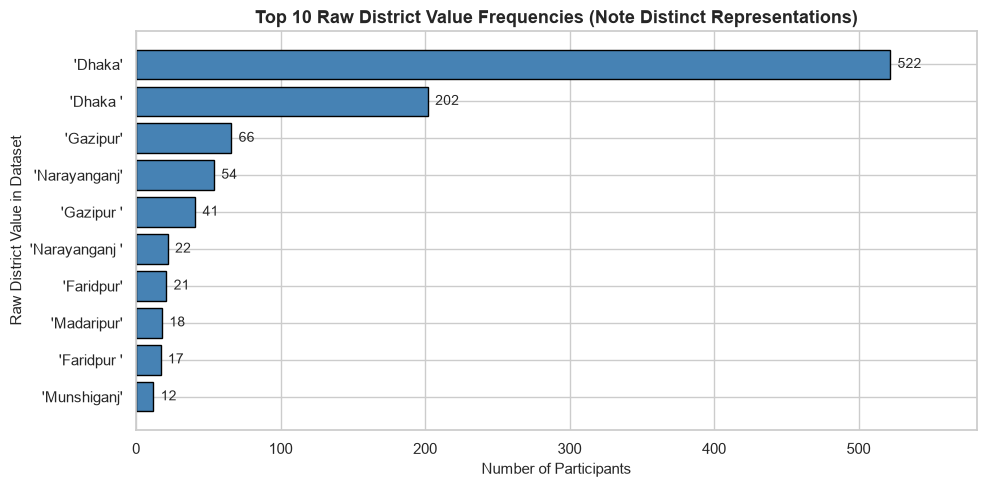

In [11]:
# Plot top 10 raw district entries
plt.figure(figsize=(10, 5))
top_raw_districts = df_raw['district'].value_counts().head(10)

bars = plt.barh(range(len(top_raw_districts)), top_raw_districts.values, color='steelblue', edgecolor='black')
plt.yticks(range(len(top_raw_districts)), [repr(d) for d in top_raw_districts.index])
plt.gca().invert_yaxis()  # Put highest count on top

plt.title("Top 10 Raw District Value Frequencies (Note Distinct Representations)", fontsize=13, weight='bold')
plt.xlabel("Number of Participants", fontsize=11)
plt.ylabel("Raw District Value in Dataset", fontsize=11)

# Annotate bar counts
for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height()/2, f"{int(width)}", va='center', fontsize=10)

plt.xlim(0, max(top_raw_districts.values) + 60)
plt.tight_layout()
plt.show()

### Interpretation
The district audit reveals two data consistency issues:
1. **Trailing Whitespace (296 records):** `'Dhaka '` (202 entries), `'Gazipur '` (41 entries), `'Narayanganj '` (22 entries), `'Faridpur '` (17 entries), `'Munshiganj '` (7 entries), `'Shariatpur '` (3 entries), `'Madaripur '` (2 entries), `'Naogaon '` (1 entry), and `'Mymensingh '` (1 entry) contain trailing spaces.
2. **Spelling Inconsistencies (4 records):**
   - `'gazipur'` (lowercase 'g') vs `'Gazipur'` (1 record)
   - `'Munsiganj'` vs `'Munshiganj'` (1 record)
   - `'Chadpur'` vs `'Chandpur'` (1 record)
   - `'Kishorganj'` vs `'Kishoreganj'` (1 record)

**Total Affected Records:** $296 \text{ (whitespace)} + 4 \text{ (spelling/casing)} = 300 \text{ records}$.

*Viva Takeaway:* This demonstrates why automated analysis requires careful initial auditing. However, as established in our guidelines, we **will not modify the raw data**. We will apply derived standardizations only when creating our working copy, preserving original values in `district_original` for transparency.

## 11. Numerical Variable Validation

### What are we doing?
We inspect the statistical distributions of all numerical features: `age`, `fever_days`, `headache_severity`, `retro_orbital_pain`, `muscle_pain`, `joint_pain`, and `vomiting_per_day`.

### Why are we doing it?
Summary statistics (mean, median, standard deviation, minimum, maximum) help us verify whether values fall within plausible survey ranges, check for extreme outliers, and assess skewness.

### What are we looking for?
- Are age values reasonable for study participants?
- Are symptom severity scores strictly within the 0 to 10 scale?
- Is vomiting frequency recorded as a count (episodes per day)?
- Are there any observations with `fever_days == 0`?

In [12]:
# Define numerical columns
numeric_cols = ['age', 'fever_days', 'headache_severity', 'retro_orbital_pain', 
                'muscle_pain', 'joint_pain', 'vomiting_per_day']

# Generate comprehensive summary statistics
num_stats = df_raw[numeric_cols].describe().T
num_stats['median'] = df_raw[numeric_cols].median()
num_stats['IQR'] = num_stats['75%'] - num_stats['25%']

# Reorder columns for readability
num_stats = num_stats[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'IQR']]

print("--- NUMERICAL VARIABLE SUMMARY STATISTICS ---")
num_stats.round(2)

--- NUMERICAL VARIABLE SUMMARY STATISTICS ---


,count,mean,std,min,25%,median,75%,max,IQR
age,1018.0,34.12,11.09,14.0,25.0,33.0,41.0,71.0,16.0
fever_days,1018.0,6.56,2.33,0.0,5.0,6.0,8.0,16.0,3.0
headache_severity,1018.0,8.51,1.70,0.0,8.0,9.0,10.0,10.0,2.0
retro_orbital_pain,1018.0,4.25,3.59,0.0,0.0,5.0,7.0,10.0,7.0
muscle_pain,1018.0,7.44,2.05,0.0,6.0,8.0,9.0,10.0,3.0
joint_pain,1018.0,6.89,2.55,0.0,5.0,8.0,9.0,10.0,4.0
vomiting_per_day,1018.0,1.98,1.55,0.0,0.0,2.0,3.0,6.0,3.0


### Verification of `fever_days = 0` (Decision 1)
Our summary statistics show a minimum `fever_days` of **0**. Let us inspect the exact records where fever duration is zero.

In [13]:
# Filter participants with 0 days of fever
zero_fever = df_raw[df_raw['fever_days'] == 0]

print(f"--- PARTICIPANTS WITH FEVER_DAYS == 0 (COUNT: {len(zero_fever)}) ---")
zero_fever[['age', 'gender', 'district', 'fever_days', 'max_temperature_f', 'headache_severity', 'dengue_result']]

--- PARTICIPANTS WITH FEVER_DAYS == 0 (COUNT: 2) ---


,age,gender,district,fever_days,max_temperature_f,headache_severity,dengue_result
73,21,Male (পুরুষ),Manikganj,0,99,5,Dengue Negative (ডেঙ্গু নেগেটিভ)
311,25,Male (পুরুষ),Dhaka,0,NaN,9,Dengue Negative (ডেঙ্গু নেগেটিভ)


### Visualizing Severity Scores and Vomiting Frequency
Let us plot boxplots for the four pain severity ratings alongside vomiting frequency to understand their distributions.

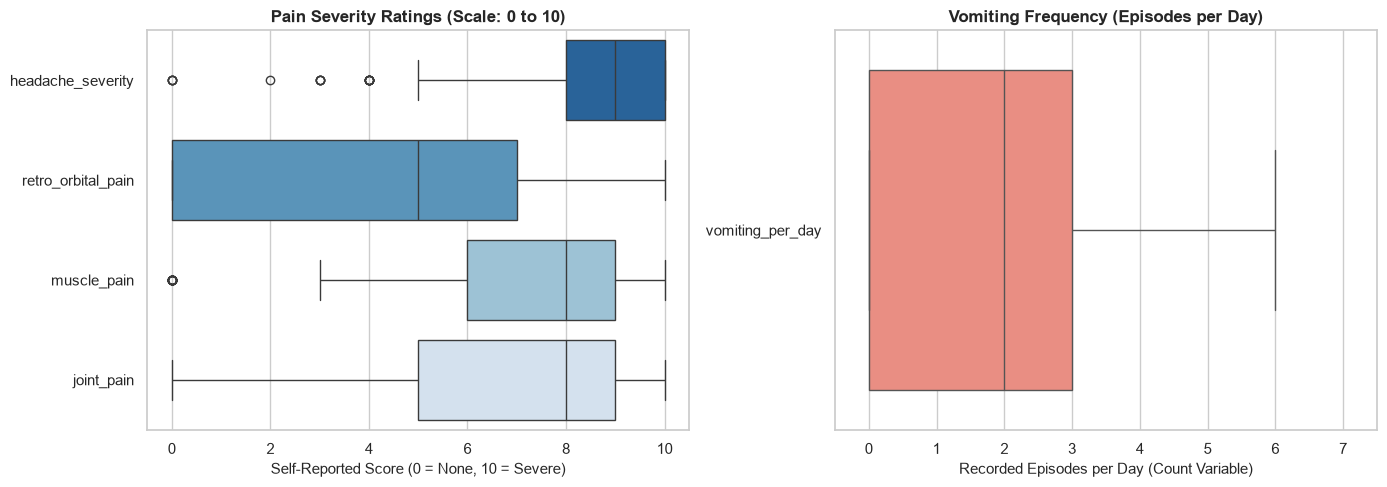

In [14]:
# Boxplot comparing pain severity scores and vomiting frequency
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Pain Severity Scores (0 to 10 Scale)
pain_vars = ['headache_severity', 'retro_orbital_pain', 'muscle_pain', 'joint_pain']
sns.boxplot(data=df_raw[pain_vars], orient='h', ax=axes[0], palette='Blues_r')
axes[0].set_title("Pain Severity Ratings (Scale: 0 to 10)", fontsize=12, weight='bold')
axes[0].set_xlabel("Self-Reported Score (0 = None, 10 = Severe)", fontsize=11)
axes[0].set_xlim(-0.5, 10.5)

# Subplot 2: Vomiting Frequency (Count of Episodes per Day)
sns.boxplot(data=df_raw[['vomiting_per_day']], orient='h', ax=axes[1], color='salmon')
axes[1].set_title("Vomiting Frequency (Episodes per Day)", fontsize=12, weight='bold')
axes[1].set_xlabel("Recorded Episodes per Day (Count Variable)", fontsize=11)
axes[1].set_xlim(-0.5, 7.5)

plt.tight_layout()
plt.show()

### Interpretation
1. **Age Range:** Participant ages span from **14 to 71 years** (mean = 34.12, median = 33.00), representing an adolescent and adult study population.
2. **Fever Duration:** Ranging from 0 to 16 days (median = 6.0 days). Exactly **2 participants (Row 73 and Row 311) reported `fever_days = 0`**, confirming our study population decision not to label all 1,018 individuals blindly as "febrile patients". Both participants who reported `fever_days = 0` belonged to the negative group.
3. **Pain Severity Scores (0–10 scale):**
   - `headache_severity`: median = 9.0
   - `muscle_pain`: median = 8.0
   - `joint_pain`: median = 8.0
   - `retro_orbital_pain`: median = 5.0 (wider distribution across participants)
   - All pain scores remain strictly within valid 0–10 bounds.
4. **Vomiting Variable Classification (Crucial Viva Point):**
   - `vomiting_per_day` ranges from 0 to 6 episodes (median = 2.0).
   - This variable measures **frequency (event count)**, not a subjective severity scale. It must be described as episodes/day.

## 12. Temperature Investigation

### What are we doing?
We conduct a dedicated, rigorous investigation of the `max_temperature_f` column to diagnose why it was stored as text, identify all problematic entries, and examine valid temperature patterns.

### Why are we doing it?
Body temperature is a primary variable in dengue-related research. However, survey and clinic datasets frequently contain data-entry anomalies or text entries in numeric fields. Understanding these issues without altering raw data is essential for scientific integrity.

### What are we looking for?
The audit identified **16 problematic temperature records**:
1. **12 missing values (`NaN`)**
2. **1 non-numeric value (`'Munshiganj'`)**
3. **1 suspicious numeric value (`'8°F'`)**
4. **2 unusually high values requiring verification (`'107°F'`)**

$$\text{Total Problematic Records} = 12 + 1 + 1 + 2 = 16$$

In [15]:
# Display raw value counts of all distinct entries in max_temperature_f
raw_temp_counts = df_raw['max_temperature_f'].value_counts(dropna=False)

print("--- ALL RAW ENTRIES IN 'max_temperature_f' ---")
for val, count in raw_temp_counts.items():
    print(f"Value: {repr(val):<15} | Count: {count:>3} records")

--- ALL RAW ENTRIES IN 'max_temperature_f' ---
Value: '104'           | Count: 272 records
Value: '103'           | Count: 230 records
Value: '102'           | Count: 200 records
Value: '101'           | Count: 143 records
Value: '105'           | Count: 114 records
Value: '106'           | Count:  21 records
Value: '100'           | Count:  21 records
Value: nan             | Count:  12 records
Value: '107'           | Count:   2 records
Value: '99'            | Count:   1 records
Value: '8'             | Count:   1 records
Value: 'Munshiganj'    | Count:   1 records


### Categorization of Problematic Temperature Entries

> “The audit identified 16 problematic temperature records: 12 missing values, 1 non-numeric value, 1 suspicious numeric value, and 2 unusually high values requiring verification.”

Let us isolate and inspect each group of problematic records:

In [16]:
# Isolate problematic temperature records
# 1. Non-numeric text values (where numeric conversion produces NaN but original was not null)
temp_numeric_test = pd.to_numeric(df_raw['max_temperature_f'], errors='coerce')
text_temp_rows = df_raw[temp_numeric_test.isna() & df_raw['max_temperature_f'].notna()]

print("--- 1. NON-NUMERIC TEXT TEMPERATURE RECORD ---")
print(f"Index: {text_temp_rows.index.tolist()}")
text_temp_rows[['district', 'fever_days', 'max_temperature_f', 'dengue_result']]

--- 1. NON-NUMERIC TEXT TEMPERATURE RECORD ---
Index: [467]


,district,fever_days,max_temperature_f,dengue_result
467,Dhaka,7,Munshiganj,Dengue Negative (ডেঙ্গু নেগেটিভ)


In [17]:
# 2. Suspicious / implausible numeric value (<= 90°F)
suspicious_temp_rows = df_raw[temp_numeric_test <= 90]

print("--- 2. SUSPICIOUS NUMERIC TEMPERATURE (8°F) ---")
print(f"Index: {suspicious_temp_rows.index.tolist()}")
suspicious_temp_rows[['district', 'fever_days', 'max_temperature_f', 'dengue_result']]

--- 2. SUSPICIOUS NUMERIC TEMPERATURE (8°F) ---
Index: [264]


,district,fever_days,max_temperature_f,dengue_result
264,Manikganj,15,8,Dengue Negative (ডেঙ্গু নেগেটিভ)


In [18]:
# 3. Unusually high temperature entries (107°F)
unusually_high_temp_rows = df_raw[temp_numeric_test >= 107]

print("--- 3. UNUSUALLY HIGH TEMPERATURE ENTRIES (107°F) ---")
print(f"Indices: {unusually_high_temp_rows.index.tolist()}")
unusually_high_temp_rows[['district', 'fever_days', 'max_temperature_f', 'dengue_result']]

--- 3. UNUSUALLY HIGH TEMPERATURE ENTRIES (107°F) ---
Indices: [2, 625]


,district,fever_days,max_temperature_f,dengue_result
2,Munshiganj,5,107,Dengue Positive (ডেঙ্গু পজিটিভ)
625,Narayanganj,7,107,Dengue Positive (ডেঙ্গু পজিটিভ)


### Recorded Numeric Temperatures Within the Analysis Range (99°F–106°F)

For this descriptive temperature analysis, recorded numeric values between 99°F and 106°F are examined as an analytical range. This filtering does not modify the underlying working dataset.

*(Important: This is an analytical filtering decision, not a medical definition of valid temperature).*

In [19]:
# Filter recorded numeric temperatures within the analysis range (99°F to 106°F)
analysis_temp_mask = temp_numeric_test.between(99, 106)
df_analysis_temp = df_raw.copy()
df_analysis_temp['temp_numeric'] = temp_numeric_test
df_analysis_temp = df_analysis_temp[analysis_temp_mask]

print(f"Total records within analysis range (99°F - 106°F): {len(df_analysis_temp)} of {len(df_raw)} ({len(df_analysis_temp)/len(df_raw)*100:.1f}%)")
print("\n--- TEMPERATURE SUMMARY BY DENGUE OUTCOME (ANALYSIS RANGE) ---")
df_analysis_temp.groupby('dengue_result')['temp_numeric'].describe().round(2)

Total records within analysis range (99°F - 106°F): 1002 of 1018 (98.4%)

--- TEMPERATURE SUMMARY BY DENGUE OUTCOME (ANALYSIS RANGE) ---


,count,mean,std,min,25%,50%,75%,max
dengue_result,,,,,,,,
Dengue Negative (ডেঙ্গু নেগেটিভ),378.0,101.75,0.96,99.0,101.0,102.0,102.0,106.0
Dengue Positive (ডেঙ্গু পজিটিভ),624.0,103.77,0.96,101.0,103.0,104.0,104.0,106.0


### Visualizing Temperature Distribution Within the Analysis Range
We now create two simple plots:
1. A histogram of temperatures within the analysis range (99°F–106°F).
2. A boxplot comparing temperature between dengue-positive and dengue-negative participants within this range.

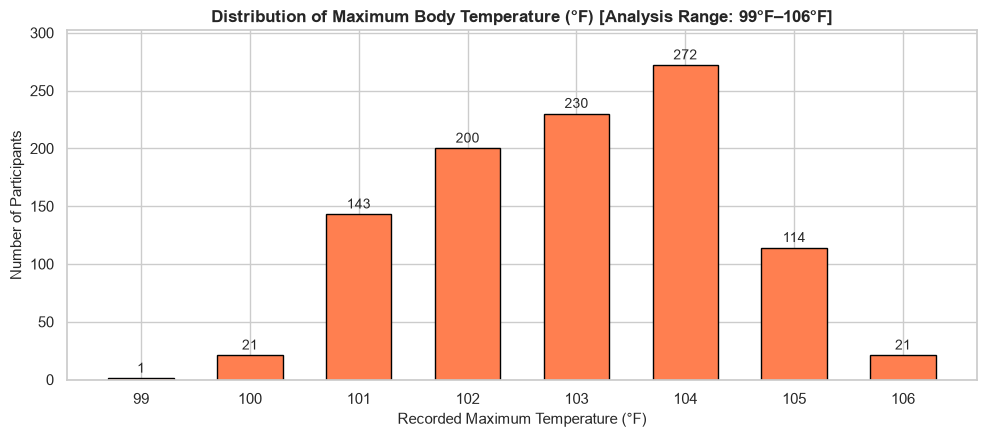

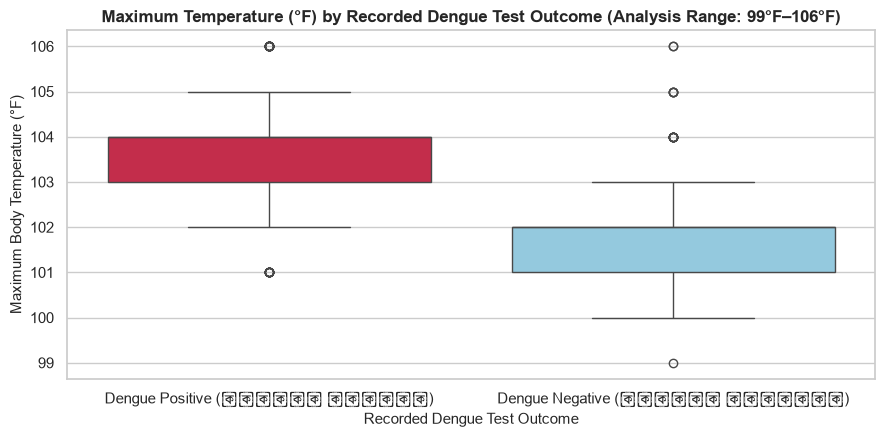

In [20]:
# Plot 1: Histogram of Temperatures within Analysis Range
plt.figure(figsize=(10, 4.5))
temp_counts = df_analysis_temp['temp_numeric'].value_counts().sort_index()

bars = plt.bar(temp_counts.index, temp_counts.values, color='coral', edgecolor='black', width=0.6)
plt.title("Distribution of Maximum Body Temperature (°F) [Analysis Range: 99°F–106°F]", fontsize=12, weight='bold')
plt.xlabel("Recorded Maximum Temperature (°F)", fontsize=11)
plt.ylabel("Number of Participants", fontsize=11)
plt.xticks(temp_counts.index)

# Add count labels above bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 5, f"{int(height)}", ha='center', fontsize=10)

plt.ylim(0, max(temp_counts.values) + 30)
plt.tight_layout()
plt.show()

# Plot 2: Temperature by Dengue Result
plt.figure(figsize=(9, 4.5))
sns.boxplot(x='dengue_result', y='temp_numeric', data=df_analysis_temp, palette=['crimson', 'skyblue'])
plt.title("Maximum Temperature (°F) by Recorded Dengue Test Outcome (Analysis Range: 99°F–106°F)", fontsize=12, weight='bold')
plt.xlabel("Recorded Dengue Test Outcome", fontsize=11)
plt.ylabel("Maximum Body Temperature (°F)", fontsize=11)
plt.tight_layout()
plt.show()

### Approved Temperature Handling Decisions
In strict accordance with our approved methodology:
- **12 Missing values:** Kept missing; no imputation is performed.
- **`'Munshiganj'` (Row 467):** The value appears inconsistent with a temperature measurement and may indicate a data-entry or column-placement issue. The original value is preserved pending verification.
- **`'8°F'` (Row 264):** Treated as a suspicious/implausible numeric value for the temperature analysis. The original value is preserved without modification.
- **`'107°F'` (Rows 2 & 625):** The two 107°F values are unusually high and have been retained without modification pending verification from the dataset creators.
- **General Principle:** No temperature values are deleted, replaced, or imputed in the dataset.

### Interpretation
- **Row 467:** Contains `'Munshiganj'` in `max_temperature_f`. The value appears inconsistent with a temperature measurement and may indicate a data-entry or column-placement issue. The original value is preserved pending verification.
- **Row 264:** Contains `'8'`. This is treated as a suspicious/implausible numeric value for temperature analysis. It is retained in the working dataset without modification, while excluded from the 99°F–106°F analytical range.
- **Rows 2 & 625:** The two 107°F values are unusually high and have been retained without modification pending verification from the dataset creators.
- **Analysis Range Comparison:** Among the 1,002 recorded entries within the 99°F–106°F analysis range, dengue-positive participants recorded a higher median temperature (**104.0°F**, IQR: 103.0–104.0) compared to dengue-negative participants (**102.0°F**, IQR: 101.0–102.0).

## 13. Dengue Outcome Distribution

### What are we doing?
We inspect the primary study outcome column, `dengue_result`, by calculating the frequency counts, group percentages, and creating a clear bar chart.

### Why are we doing it?
Understanding the balance between dengue-positive and dengue-negative cases is critical before conducting comparative subgroup analyses.

### What are we looking for?
- What are the unique outcome categories?
- Are there any missing, unassigned, or ambiguous outcome categories?
- What proportion of participants tested positive?

In [21]:
# Calculate frequency counts and percentages of the dengue outcome
outcome_counts = df_raw['dengue_result'].value_counts(dropna=False)
outcome_pcts = (df_raw['dengue_result'].value_counts(normalize=True, dropna=False) * 100).round(2)

# Combine into a clean presentation table
outcome_summary = pd.DataFrame({
    'Dengue Test Outcome': outcome_counts.index,
    'Participant Count': outcome_counts.values,
    'Percentage (%)': outcome_pcts.values
})

print("--- DENGUE OUTCOME DISTRIBUTION ---")
outcome_summary

--- DENGUE OUTCOME DISTRIBUTION ---


,Dengue Test Outcome,Participant Count,Percentage (%)
0,Dengue Positive (ডেঙ্গু পজিটিভ),630,61.89
1,Dengue Negative (ডেঙ্গু নেগেটিভ),388,38.11


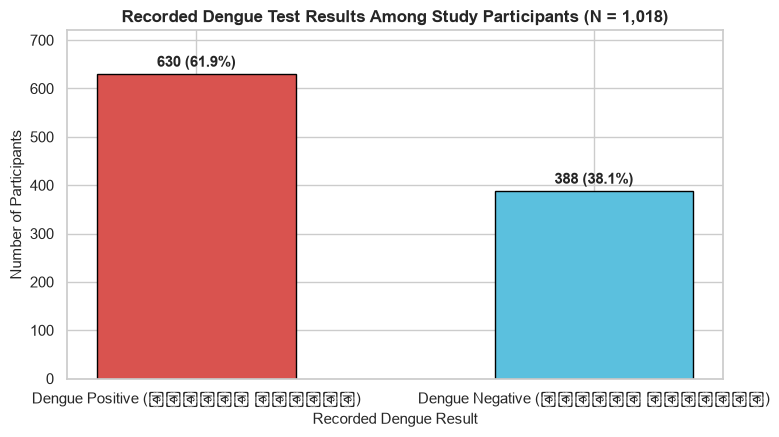

In [22]:
# Visualization: Dengue Outcome Distribution Bar Chart
plt.figure(figsize=(8, 4.5))
bars = plt.bar(outcome_summary['Dengue Test Outcome'], outcome_summary['Participant Count'], 
               color=['#d9534f', '#5bc0de'], edgecolor='black', width=0.5)

plt.title("Recorded Dengue Test Results Among Study Participants (N = 1,018)", fontsize=12, weight='bold')
plt.xlabel("Recorded Dengue Result", fontsize=11)
plt.ylabel("Number of Participants", fontsize=11)

# Annotate counts and percentages
for bar in bars:
    height = bar.get_height()
    pct = (height / len(df_raw)) * 100
    plt.text(bar.get_x() + bar.get_width()/2, height + 15, f"{int(height)} ({pct:.1f}%)", 
             ha='center', fontsize=11, weight='bold')

plt.ylim(0, max(outcome_counts.values) + 90)
plt.tight_layout()
plt.show()

### Crucial Viva & Communication Precaution
> **IMPORTANT DISTINCTION:**  
> The dengue-positive proportion within this dataset was **61.89%** (630 out of 1,018 study participants).  
> The dataset contains survey-based participant records with recorded dengue test results.  
> This number is strictly described as:  
> **"Dengue-positive proportion among study participants in this dataset."**  
> It must NOT be described as Bangladesh's national dengue prevalence.

### Interpretation
- Total study participants: **1,018**
- **Dengue Positive:** 630 participants (**61.89%**)
- **Dengue Negative:** 388 participants (**38.11%**)
- **Missing/Unknown:** 0 records (100% complete outcome documentation).

## 14. Data Quality Assessment

### What are we doing?
We consolidate all observed anomalies and data characteristics into a formal **Data Quality Assessment Table**, ranking each issue by severity.

### Why are we doing it?
In professional data science and academic research, data issues must be documented transparently before any cleaning takes place. Assigning severity levels ensures that critical issues are addressed safely and prevents premature, undocumented alterations.

### Severity Rating Definitions:
- **Critical:** Data issues that cause code to crash or produce fundamentally false statistical results if unhandled.
- **High:** Substantial data inconsistencies (such as category fragmentation) that affect sample counts across key variables.
- **Medium:** Minor variations or plausible extreme values requiring verification.
- **Low:** Cosmetic formatting differences (such as bilingual parenthetical translations).
- **No Issue:** Variables confirmed to be clean and within valid ranges.

---

### Data Quality Assessment Table

| Issue Identified | Variable Affected | Severity | Records Affected | Why It Matters | Proposed Action |
|---|---|---:|---:|---|---|
| Non-numeric text value (`'Munshiganj'`) | `max_temperature_f` | **High** | 1 record (Row 467) | The value appears inconsistent with a temperature measurement and may indicate a data-entry or column-placement issue. | Do not delete or overwrite raw file; preserve original value pending verification. |
| Suspicious / implausible numeric value (`'8°F'`) | `max_temperature_f` | **High** | 1 record (Row 264) | Suspicious numerical value for temperature analysis; would distort mean/median if included without filtering. | Keep unchanged in working copy; exclude from descriptive 99°F–106°F temperature analysis range pending verification. |
| Missing temperature values | `max_temperature_f` | **Medium** | 12 records | Incomplete temperature records for 1.18% of participants. | Do not impute with mean/median; leave missing values unavailable during temperature calculations. |
| Unusually high temperature values (`'107°F'`) | `max_temperature_f` | **Medium** | 2 records (Rows 2, 625) | Unusually high readings requiring verification from dataset creators. | Retain without modification pending verification from dataset creators. |
| Trailing whitespace in district names | `district` | **High** | 296 records (`'Dhaka '`, `'Gazipur '`, etc.) | Splinters district categories (e.g. `'Dhaka '` vs `'Dhaka'`), distorting geographical counts. | Derived standardization change: apply `.str.strip()` on working copy; preserve original in `district_original`. |
| District spelling & casing variants | `district` | **Medium** | 4 records (`'gazipur'`, `'Munsiganj'`, `'Chadpur'`, `'Kishorganj'`) | Fragments district frequencies into duplicate categories. | Derived standardization change: apply approved mapping dictionary on working copy; preserve original in `district_original`. |
| Zero fever duration (`fever_days = 0`) | `fever_days` | **Low** | 2 records (Rows 73, 311) | Inaccurate to describe all 1,018 individuals as "febrile patients". | Adopt approved wording: "study participants" or "participants with recorded dengue test results". |
| Bilingual text format | Categorical columns | **Low** | All records | Requires consistent string matching when filtering categories. | Handle cleanly with standard equality comparisons; keep labels readable for general public. |
| Duplicate rows | Entire dataset | **No Issue** | 0 records | Dataset has no redundant identical records. | No deduplication needed. |

## 15. Cleaning Decisions

### What are we doing?
We formally establish our cleaning plan before writing any transformation code, distinguishing the **observed problem**, the **proposed solution**, and the **actual transformation to be performed**.

### Why are we doing it?
A core rule of reproducible research is that **we do not clean automatically just because an issue exists**. Every transformation must have a documented rationale, a defined scope, and an assessment of analytical risk.

---

### Cleaning Plan Summary Table

| Identified Issue | Proposed Action | Methodological Reason | Records Affected | Analytical Risk & Mitigation |
|---|---|---|---:|---|
| District whitespace & misspellings | Derived standardization on working copy using approved mapping dictionary and whitespace stripping. | Ensures accurate geographic aggregation while preserving the raw audit trail. | 300 records (296 whitespace + 4 spelling/casing) | **Risk:** Overwriting raw research records. <br>**Mitigation:** Save original values in a separate column (`district_original`). |
| 16 Problematic temperature records (12 missing, 1 text, 1 suspicious, 2 unusually high) | **No deletion, no replacement, no imputation.** Retain entries as-is in working copy. | Silent imputation creates false precision; silent deletion reduces sample size. | 16 records total | **Risk:** Calculations failing on text. <br>**Mitigation:** Handle missing/suspicious dynamically only in temperature-specific analyses. |
| Zero fever days (`fever_days = 0`) | **No record deletion.** Retain both records in working copy. | Records reflect legitimate study participants who reported `fever_days = 0` and received tests. | 2 records | **Risk:** Misrepresenting cohort. <br>**Mitigation:** Use approved "study participant" terminology. |
| Raw dataset protection | Create an isolated working DataFrame (`df_working`) and export to a dedicated working CSV. | Guaranteed immutability of original raw research file. | All 1,018 records | **Risk:** Accidental overwrite. <br>**Mitigation:** Working file uses a clearly distinguished filename; verified via SHA-256 hash. |

## 16. Create Working Copy

### What are we doing?
We create an independent working copy (`df_working = df_raw.copy()`), create a backup column (`district_original`) containing untouched district entries, apply the approved derived district standardizations, and export the validated working DataFrame to a separate CSV file.

### Why are we doing it?
This ensures the raw research file remains 100% untouched while giving us a clean, defensible working dataset for subsequent exploratory analysis.

### Approved District Mapping Rules (Derived Standardization):
```python
{
    "gazipur": "Gazipur",
    "Munsiganj": "Munshiganj",
    "Chadpur": "Chandpur",
    "Kishorganj": "Kishoreganj"
}
```
Along with `.str.strip()` to eliminate leading and trailing whitespace.

In [23]:
# Step 1: Create an independent working copy of the dataset
# df_raw remains strictly unmodified
df_working = df_raw.copy()

# Step 2: Preserve original district values in a dedicated column
df_working['district_original'] = df_working['district']

# Step 3: Define approved district standardization mapping
district_mapping = {
    "gazipur": "Gazipur",
    "Munsiganj": "Munshiganj",
    "Chadpur": "Chandpur",
    "Kishorganj": "Kishoreganj"
}

# Step 4: Apply whitespace removal followed by dictionary replacement
# Notice we first strip whitespace, then apply the approved corrections
df_working['district'] = df_working['district'].str.strip().replace(district_mapping)

# Step 5: Calculate exact number of affected records
affected_mask = df_working['district'] != df_working['district_original']
affected_count = affected_mask.sum()

print("--- WORKING COPY CREATION & DISTRICT STANDARDIZATION ---")
print(f"Total rows in working copy     : {len(df_working)}")
print(f"Total columns in working copy  : {len(df_working.columns)} (added 'district_original')")
print(f"District records standardized  : {affected_count} records")

--- WORKING COPY CREATION & DISTRICT STANDARDIZATION ---
Total rows in working copy     : 1018
Total columns in working copy  : 24 (added 'district_original')
District records standardized  : 300 records


In [24]:
# Compare District Unique Counts Before and After Standardization
print("--- DISTRICT STANDARDIZATION RESULTS ---")
print(f"Distinct district entries BEFORE cleaning : {df_working['district_original'].nunique()}")
print(f"Distinct district entries AFTER cleaning  : {df_working['district'].nunique()}")

print("\nCleaned District Distribution:")
df_working['district'].value_counts()

--- DISTRICT STANDARDIZATION RESULTS ---
Distinct district entries BEFORE cleaning : 28
Distinct district entries AFTER cleaning  : 18

Cleaned District Distribution:


district
Dhaka          724
Gazipur        108
Narayanganj     76
Faridpur        38
Munshiganj      20
Madaripur       20
Manikganj       11
Shariatpur       7
Mymensingh       4
Cumilla          2
Naogaon          1
Narsingdi        1
Barishal         1
Tangail          1
Chandpur         1
Lakshmipur       1
Noakhali         1
Kishoreganj      1
Name: count, dtype: int64

In [25]:
# Step 6: Export working dataset to a separate, clearly named CSV file
# This file will be used for subsequent EDA and analysis.
working_csv_path = Path("data/processed/Dengue_Raw_Research_Data_v1_working.csv")

# Support execution from either the repository root or the notebooks folder
if not working_csv_path.parent.exists():
    working_csv_path = Path("../data/processed/Dengue_Raw_Research_Data_v1_working.csv")

df_working.to_csv(working_csv_path, index=False)
print(f"Working copy successfully saved to: {working_csv_path.resolve()}")
print(f"File size on disk: {os.path.getsize(working_csv_path):,} bytes")

Working copy successfully saved to: E:\Download\PDS MID\dengue-symptom-exposure-analysis\data\processed\Dengue_Raw_Research_Data_v1_working.csv
File size on disk: 406,766 bytes


### Interpretation
**Exactly 300 records were affected by district standardization: 296 records required whitespace trimming and 4 records required the approved spelling/casing mappings.**

- Original unique district strings: **28**
- Cleaned unique district strings: **18**
- The raw dataset remains unmodified, and the original values are permanently preserved in `district_original`.

## 17. Validate Working Copy

### What are we doing?
We execute a battery of automated validation assertions to verify the integrity, consistency, and safety of our working copy before proceeding to any exploratory analysis.

### Why are we doing it?
Validation guarantees that no unintended side-effects occurred during data processing:
- 1,018 rows remain.
- Original observations have not been deleted.
- Raw data were not modified (cryptographically verified via SHA-256 hash).
- `district_original` exists.
- District standardization was applied only to the working copy.
- 12 missing temperature values remain missing.
- 1 non-numeric temperature value is identified.
- 1 suspicious `8°F` value is identified.
- 2 `107°F` values remain present.
- No temperature imputation occurred.
- The two `fever_days = 0` observations remain.
- No unexpected row deletion occurred.

### What are we looking for?
Every validation test must output a **PASS** status.

In [26]:
# Execute systematic validation assertions confirming all agreed decisions
validation_results = []

# 1. 1,018 rows remain
check_1 = len(df_working) == 1018
validation_results.append(("1,018 Rows Remain", check_1, f"{len(df_working)} rows"))

# 2. Original observations have not been deleted
check_2 = len(df_working) == len(df_raw)
validation_results.append(("No Original Observations Deleted", check_2, "1,018 == 1,018"))

# 3. Raw CSV File Integrity (SHA-256 hash unchanged)
raw_file_hash_current = calculate_file_hash(raw_data_path)
check_3 = (raw_file_hash_current == raw_file_hash_original) and (len(pd.read_csv(raw_data_path)) == 1018)
validation_results.append(("Raw CSV File Integrity (SHA-256 Unchanged)", check_3, f"SHA-256: {raw_file_hash_current[:16]}... (identical)"))

# 4. district_original exists
check_4 = 'district_original' in df_working.columns
validation_results.append(("'district_original' Column Exists", check_4, "Column preserved"))

# 5. District standardization applied only to working copy
check_5 = (df_working['district_original'] == df_raw['district']).all() and df_working['district'].nunique() == 18
validation_results.append(("District Standardization on Working Copy Only", check_5, "18 clean districts, raw intact"))

# 6. 12 missing temperature values remain missing
check_6 = df_working['max_temperature_f'].isna().sum() == 12
validation_results.append(("12 Missing Temperatures Remain Missing", check_6, "Exactly 12 nulls"))

# 7. 1 non-numeric temperature value is identified ('Munshiganj')
check_7 = (df_working['max_temperature_f'] == 'Munshiganj').sum() == 1
validation_results.append(("1 Non-Numeric Temperature Identified ('Munshiganj')", check_7, "Preserved at index 467"))

# 8. 1 suspicious 8°F value is identified
check_8 = (df_working['max_temperature_f'] == '8').sum() == 1
validation_results.append(("1 Suspicious 8°F Value Identified", check_8, "Preserved at index 264"))

# 9. 2 107°F values remain present
check_9 = (df_working['max_temperature_f'] == '107').sum() == 2
validation_results.append(("2 Unusually High 107°F Values Present", check_9, "Preserved at indices 2, 625"))

# 10. No temperature imputation occurred
check_10 = df_working['max_temperature_f'].equals(df_raw['max_temperature_f'])
validation_results.append(("No Temperature Imputation Occurred", check_10, "100% identical to raw entries"))

# 11. The two fever_days = 0 observations remain
check_11 = (df_working['fever_days'] == 0).sum() == 2
validation_results.append(("Two 'fever_days = 0' Observations Retained", check_11, "Indices 73 and 311 intact"))

# 12. No unexpected row deletion occurred
check_12 = df_working.notna().sum()['age'] == 1018
validation_results.append(("No Unexpected Row Deletion Occurred", check_12, "All 1,018 participant rows present"))

# Format validation summary table
val_df = pd.DataFrame(validation_results, columns=['Validation Check', 'Status', 'Details'])
val_df['Status'] = val_df['Status'].map({True: '✅ PASS', False: '❌ FAIL'})

print("--- WORKING COPY VALIDATION AUDIT ---")
val_df

--- WORKING COPY VALIDATION AUDIT ---


,Validation Check,Status,Details
0,"1,018 Rows Remain",✅ PASS,1018 rows
1,No Original Observations Deleted,✅ PASS,"1,018 == 1,018"
2,Raw CSV File Integrity (SHA-256 Unchanged),✅ PASS,SHA-256: 2fe2621d35a42223... (identical)
3,'district_original' Column Exists,✅ PASS,Column preserved
4,District Standardization on Working Copy Only,✅ PASS,"18 clean districts, raw intact"
5,12 Missing Temperatures Remain Missing,✅ PASS,Exactly 12 nulls
6,1 Non-Numeric Temperature Identified ('Munshig...,✅ PASS,Preserved at index 467
7,1 Suspicious 8°F Value Identified,✅ PASS,Preserved at index 264
8,2 Unusually High 107°F Values Present,✅ PASS,"Preserved at indices 2, 625"
9,No Temperature Imputation Occurred,✅ PASS,100% identical to raw entries


### Validation Status
The raw dataset remains unchanged (cryptographically verified via SHA-256 hash), and all current analysis decisions have been applied only to the working copy. The audit identified 16 problematic temperature records: 12 missing values, 1 non-numeric value, 1 suspicious numeric value, and 2 unusually high values requiring verification. No temperature values were imputed or silently replaced. The two observations with `fever_days = 0` were retained, so “study participants” is used as the neutral population description. District standardization was applied only as a documented derived transformation, with original district values preserved in `district_original`: **296 whitespace-affected records + 4 spelling/casing corrections = 300 standardized records.**

The working copy has passed all validation checks. We now proceed directly to the Exploratory Data Analysis.

## 18. Research Question Analysis (Exploratory Data Analysis)

In this section, we conduct the exploratory data analysis (EDA) using the validated working dataset (`df_working`). We address each of our four approved research questions sequentially.

### 18.1 RQ1: Fever Characteristics

> **Research Question 1:**  
> *How do fever duration and maximum temperature differ between dengue-positive and dengue-negative participants?*

#### What are we checking?
We examine:
1. **Fever duration (`fever_days`):** Distribution, median, mean, IQR, minimum, and maximum across dengue-positive and dengue-negative groups.
2. **Maximum body temperature (`max_temperature_f`):** Distribution within the predefined analytical temperature range (99°F–106°F).

#### Why are we checking it?
Fever is the hallmark presentation of acute febrile illnesses in Bangladesh. Understanding how fever duration and peak recorded temperature compare between those with positive versus negative dengue test results provides foundational insight into presentation patterns in this dataset.

#### What decision was made?
- For fever duration, all 1,018 participants are included (including the 2 participants with `fever_days = 0`).
- For temperature comparison, we apply our previously established **analytical filtering decision: 99°F–106°F**.
- Exactly **16 problematic records are excluded from the temperature-specific comparison** (12 missing `NaN`, 1 non-numeric `'Munshiganj'`, 1 suspicious `'8°F'`, and 2 unusually high `'107°F'`), without modifying the underlying working dataset.

In [27]:
# RQ1: Calculate summary statistics for fever duration by dengue outcome
fever_days_stats = df_working.groupby('dengue_result')['fever_days'].agg(
    Count='count',
    Median='median',
    Mean='mean',
    Std='std',
    Q25=lambda x: x.quantile(0.25),
    Q75=lambda x: x.quantile(0.75),
    Min='min',
    Max='max'
)
fever_days_stats['IQR'] = fever_days_stats['Q75'] - fever_days_stats['Q25']
fever_days_stats = fever_days_stats[['Count', 'Median', 'IQR', 'Mean', 'Std', 'Min', 'Max']].round(2)

print("--- FEVER DURATION (DAYS) BY DENGUE OUTCOME ---")
fever_days_stats

--- FEVER DURATION (DAYS) BY DENGUE OUTCOME ---


,Count,Median,IQR,Mean,Std,Min,Max
dengue_result,,,,,,,
Dengue Negative (ডেঙ্গু নেগেটিভ),388,6.0,3.0,6.28,2.52,0,16
Dengue Positive (ডেঙ্গু পজিটিভ),630,7.0,3.0,6.73,2.18,3,15


In [28]:
# RQ1: Calculate summary statistics for maximum temperature within the 99°F-106°F analytical range
# Convert temperature to numeric dynamically for this calculation
temp_numeric_series = pd.to_numeric(df_working['max_temperature_f'], errors='coerce')
valid_temp_mask = temp_numeric_series.between(99, 106)

# Create a temporary subset for temperature analysis only
df_temp_analysis = df_working[valid_temp_mask].copy()
df_temp_analysis['temp_num'] = temp_numeric_series[valid_temp_mask]

# Compute summary statistics
temp_stats = df_temp_analysis.groupby('dengue_result')['temp_num'].agg(
    Count='count',
    Median='median',
    Mean='mean',
    Std='std',
    Q25=lambda x: x.quantile(0.25),
    Q75=lambda x: x.quantile(0.75),
    Min='min',
    Max='max'
)
temp_stats['IQR'] = temp_stats['Q75'] - temp_stats['Q25']
temp_stats = temp_stats[['Count', 'Median', 'IQR', 'Mean', 'Std', 'Min', 'Max']].round(2)

excluded_count = len(df_working) - len(df_temp_analysis)
print(f"Total participants in temperature analysis range (99°F–106°F): {len(df_temp_analysis)} (Excluded: {excluded_count} problematic records)")
print("--- MAXIMUM TEMPERATURE (°F) BY DENGUE OUTCOME (99°F–106°F RANGE) ---")
temp_stats

Total participants in temperature analysis range (99°F–106°F): 1002 (Excluded: 16 problematic records)
--- MAXIMUM TEMPERATURE (°F) BY DENGUE OUTCOME (99°F–106°F RANGE) ---


,Count,Median,IQR,Mean,Std,Min,Max
dengue_result,,,,,,,
Dengue Negative (ডেঙ্গু নেগেটিভ),378,102.0,1.0,101.75,0.96,99.0,106.0
Dengue Positive (ডেঙ্গু পজিটিভ),624,104.0,1.0,103.77,0.96,101.0,106.0


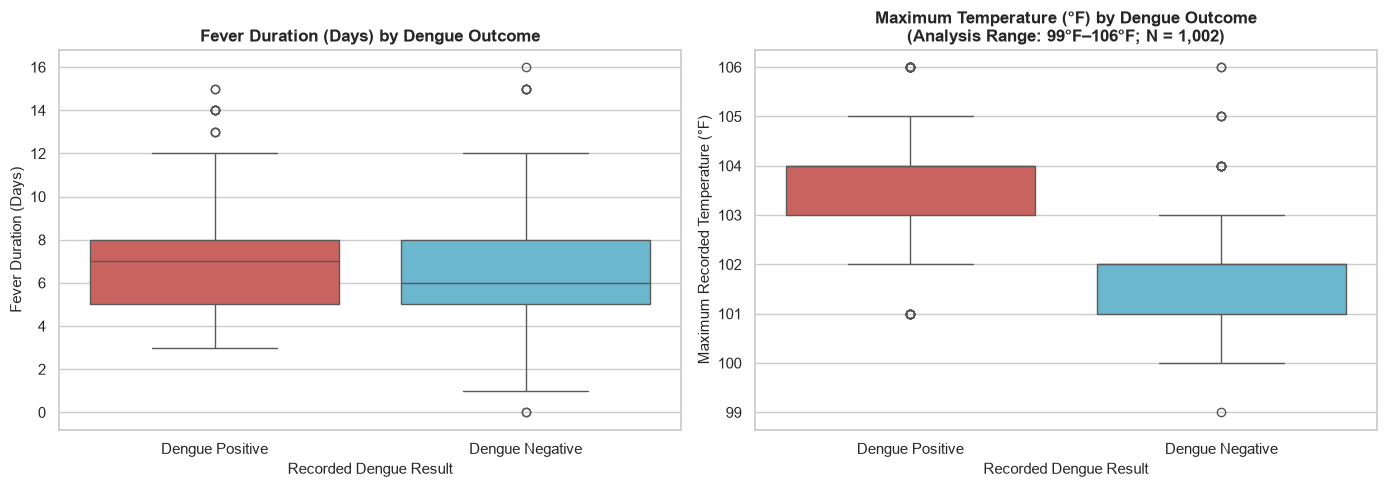

In [29]:
# Visualization for RQ1: Comparative Boxplots for Fever Duration and Maximum Temperature
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1A: Fever Duration Boxplot
palette_colors = {'Dengue Positive (ডেঙ্গু পজিটিভ)': '#d9534f', 'Dengue Negative (ডেঙ্গু নেগেটিভ)': '#5bc0de'}

sns.boxplot(x='dengue_result', y='fever_days', data=df_working, ax=axes[0], palette=palette_colors)
axes[0].set_title("Fever Duration (Days) by Dengue Outcome", fontsize=12, weight='bold')
axes[0].set_xlabel("Recorded Dengue Result", fontsize=11)
axes[0].set_ylabel("Fever Duration (Days)", fontsize=11)
axes[0].set_xticklabels(['Dengue Positive', 'Dengue Negative'])

# Plot 1B: Maximum Temperature Boxplot (within analytical range)
sns.boxplot(x='dengue_result', y='temp_num', data=df_temp_analysis, ax=axes[1], palette=palette_colors)
axes[1].set_title("Maximum Temperature (°F) by Dengue Outcome\n(Analysis Range: 99°F–106°F; N = 1,002)", fontsize=12, weight='bold')
axes[1].set_xlabel("Recorded Dengue Result", fontsize=11)
axes[1].set_ylabel("Maximum Recorded Temperature (°F)", fontsize=11)
axes[1].set_xticklabels(['Dengue Positive', 'Dengue Negative'])

plt.tight_layout()
plt.show()

#### Interpretation of RQ1 Findings
1. **Fever Duration:**
   - **Dengue-Positive:** Median fever duration was **7.0 days** (IQR: 3.0 days, Q1=5.0, Q3=8.0; Mean: 6.73 days; Range: 3 to 15 days).
   - **Dengue-Negative:** Median fever duration was **6.0 days** (IQR: 3.0 days, Q1=5.0, Q3=8.0; Mean: 6.28 days; Range: 0 to 16 days).
   - Both groups showed similar typical durations (IQR of 3.0 days), with dengue-positive participants having a slightly higher median (+1 day). Both participants who reported `fever_days = 0` belonged to the negative group.
2. **Maximum Temperature:**
   - Exactly **16 records were excluded** from this specific comparison (12 missing, 1 `'Munshiganj'`, 1 `'8°F'`, 2 `'107°F'`), leaving 1,002 evaluated records (624 positive, 378 negative).
   - **Dengue-Positive:** Median temperature was **104.0°F** (IQR: 1.0°F, Q1=103.0, Q3=104.0; Mean: 103.77°F).
   - **Dengue-Negative:** Median temperature was **102.0°F** (IQR: 1.0°F, Q1=101.0, Q3=102.0; Mean: 101.75°F).
   - Within the predefined analytical range, dengue-positive participants had a higher median recorded temperature than dengue-negative participants.
   - *Non-causal note:* These are observational differences in this dataset and do not establish causation.

### 18.2 RQ2: Early Symptoms Differentials

> **Research Question 2:**  
> *Which early symptoms—nausea, fatigue, appetite loss, abdominal pain, diarrhea, bleeding, and rash—show the largest differences between dengue-positive and dengue-negative participants?*

#### What are we checking?
We examine the presence of seven early symptoms:
- `early_nausea`
- `early_fatigue`
- `early_appetite_loss`
- `early_abdominal_pain`
- `early_diarrhea`
- `early_bleeding`
- `early_rash`

#### Why are we checking it?
During early consultation, participants present with non-specific constitutional and gastrointestinal complaints. Identifying which symptoms show the largest divergence between test-positive and test-negative individuals helps illustrate the symptom profile of participants in this dataset.

#### Metric Definition:
$$\text{Percentage-Point Difference} = \text{Percentage among Dengue-Positive} - \text{Percentage among Dengue-Negative}$$
We avoid relative risk metrics because this is a cross-sectional dataset of tested individuals; percentage-point differences directly and transparently answer which symptoms show the largest differences.

In [30]:
# RQ2: Calculate symptom percentages and percentage-point differences
symptom_list = [
    ('early_appetite_loss', 'Appetite Loss'),
    ('early_fatigue', 'Fatigue / Weakness'),
    ('early_nausea', 'Nausea'),
    ('early_bleeding', 'Bleeding Manifestations'),
    ('early_rash', 'Skin Rash'),
    ('early_diarrhea', 'Diarrhea / Loose Stool'),
    ('early_abdominal_pain', 'Abdominal Pain')
]

pos_cohort = df_working[df_working['dengue_result'].str.startswith('Dengue Positive')]
neg_cohort = df_working[df_working['dengue_result'].str.startswith('Dengue Negative')]

symptom_summary_rows = []
for col_name, display_name in symptom_list:
    # Calculate percentages of 'Yes' responses
    pos_pct = (pos_cohort[col_name].str.startswith('Yes')).mean() * 100
    neg_pct = (neg_cohort[col_name].str.startswith('Yes')).mean() * 100
    pp_diff = pos_pct - neg_pct
    
    symptom_summary_rows.append({
        'Symptom': display_name,
        'Variable': col_name,
        'Dengue Positive (%)': round(pos_pct, 2),
        'Dengue Negative (%)': round(neg_pct, 2),
        'Difference (pp)': round(pp_diff, 2)
    })

# Convert to DataFrame and sort by percentage-point difference descending
df_rq2 = pd.DataFrame(symptom_summary_rows).sort_values(by='Difference (pp)', ascending=False).reset_index(drop=True)

print("--- EARLY SYMPTOM DIFFERENTIALS (SORTED BY PERCENTAGE-POINT DIFFERENCE) ---")
df_rq2

--- EARLY SYMPTOM DIFFERENTIALS (SORTED BY PERCENTAGE-POINT DIFFERENCE) ---


,Symptom,Variable,Dengue Positive (%),Dengue Negative (%),Difference (pp)
0,Appetite Loss,early_appetite_loss,99.21,29.90,69.31
1,Fatigue / Weakness,early_fatigue,99.68,40.98,58.70
2,Nausea,early_nausea,98.73,65.72,33.01
3,Bleeding Manifestations,early_bleeding,7.14,2.84,4.31
4,Skin Rash,early_rash,21.11,23.45,-2.34
5,Diarrhea / Loose Stool,early_diarrhea,40.79,62.63,-21.84
6,Abdominal Pain,early_abdominal_pain,23.33,56.19,-32.85


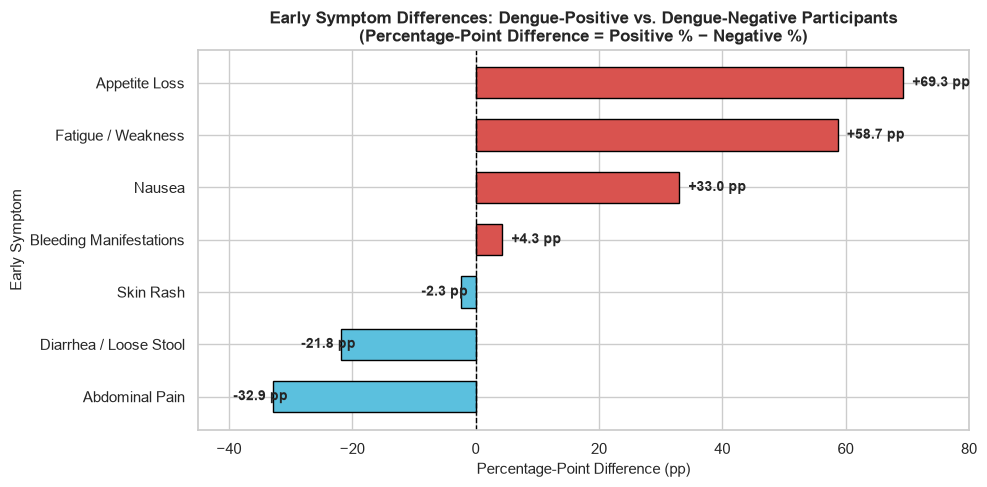

In [31]:
# Visualization for RQ2: Horizontal Bar Chart of Percentage-Point Differences
plt.figure(figsize=(10, 5))

# Color bars by direction of difference: coral for positive difference, skyblue for negative difference
bar_colors = ['#d9534f' if x > 0 else '#5bc0de' for x in df_rq2['Difference (pp)']]

bars = plt.barh(df_rq2['Symptom'], df_rq2['Difference (pp)'], color=bar_colors, edgecolor='black', height=0.6)
plt.gca().invert_yaxis()  # Largest positive difference on top

plt.axvline(0, color='black', linewidth=1, linestyle='--')
plt.title("Early Symptom Differences: Dengue-Positive vs. Dengue-Negative Participants\n(Percentage-Point Difference = Positive % − Negative %)", fontsize=12, weight='bold')
plt.xlabel("Percentage-Point Difference (pp)", fontsize=11)
plt.ylabel("Early Symptom", fontsize=11)

# Annotate values beside bars
for bar in bars:
    width = bar.get_width()
    offset = 1.5 if width >= 0 else -6.5
    plt.text(width + offset, bar.get_y() + bar.get_height()/2, f"{width:+.1f} pp", 
             va='center', fontsize=10, weight='bold')

plt.xlim(-45, 80)
plt.tight_layout()
plt.show()

#### Interpretation of RQ2 Findings
1. **Largest Positive Differentials (Observed Substantially More in Dengue-Positive Group):**
   - **Appetite Loss:** Present in **99.21%** of dengue-positive vs. **29.90%** of dengue-negative participants (**+69.31 percentage points**). This showed the largest single difference in the dataset.
   - **Fatigue / Weakness:** Present in **99.68%** of dengue-positive vs. **40.98%** of dengue-negative participants (**+58.70 percentage points**).
   - **Nausea:** Present in **98.73%** of dengue-positive vs. **65.72%** of dengue-negative participants (**+33.01 percentage points**).
2. **Minor Differentials:**
   - **Bleeding:** Low overall frequency, but slightly higher in positive group (**7.14%** vs. **2.84%**, **+4.31 pp**).
   - **Skin Rash:** Present in similar proportions in both groups (**21.11%** vs. **23.45%**, **-2.34 pp**).
3. **Negative Differentials (Observed More in Dengue-Negative Group):**
   - **Diarrhea:** Present in **40.79%** of positive vs. **62.63%** of negative participants (**-21.84 percentage points**).
   - **Abdominal Pain:** Present in **23.33%** of positive vs. **56.19%** of negative participants (**-32.85 percentage points**).
   - *Analytical takeaway:* Appetite loss and fatigue/weakness showed the largest observed percentage-point differences between the dengue-positive and dengue-negative groups. Localized gastrointestinal symptoms (abdominal pain, diarrhea) were reported more frequently among dengue-negative individuals.

### 18.3 RQ3: Symptom Severity Scores and Vomiting Frequency

> **Research Question 3:**  
> *How do symptom severity scores for headache, retro-orbital pain, muscle pain, and joint pain, along with vomiting frequency, differ between dengue-positive and dengue-negative participants?*

#### What are we checking?
We examine:
- Four subjective **Pain Severity Scores (0–10 scale)**:
  - `headache_severity` — self-reported score (0 = None, 10 = Severe)
  - `retro_orbital_pain` — self-reported score (0 = None, 10 = Severe)
  - `muscle_pain` — self-reported score (0 = None, 10 = Severe)
  - `joint_pain` — self-reported score (0 = None, 10 = Severe)
- One frequency/count variable:
  - `vomiting_per_day` — self-reported number of vomiting episodes per day (range 0–6).

#### Important Methodological Distinction for Viva:
`vomiting_per_day` is a **self-reported frequency/count variable** measuring daily episodes. It is **NOT** a subjective severity rating scale and must never be described as a severity score.

In [32]:
# RQ3: Calculate summary statistics for pain severity scores and vomiting frequency
severity_vars = [
    ('headache_severity', 'Headache Severity', 'Score (0–10)'),
    ('retro_orbital_pain', 'Retro-Orbital Pain', 'Score (0–10)'),
    ('muscle_pain', 'Muscle Pain (Myalgia)', 'Score (0–10)'),
    ('joint_pain', 'Joint Pain (Arthralgia)', 'Score (0–10)'),
    ('vomiting_per_day', 'Vomiting Frequency', 'Episodes/Day (Count)')
]

severity_summary_list = []
for var_col, var_label, scale_type in severity_vars:
    pos_data = pos_cohort[var_col]
    neg_data = neg_cohort[var_col]
    
    severity_summary_list.append({
        'Variable': var_label,
        'Measurement Scale': scale_type,
        'Pos Median': pos_data.median(),
        'Pos IQR': round(pos_data.quantile(0.75) - pos_data.quantile(0.25), 2),
        'Pos Mean': round(pos_data.mean(), 2),
        'Neg Median': neg_data.median(),
        'Neg IQR': round(neg_data.quantile(0.75) - neg_data.quantile(0.25), 2),
        'Neg Mean': round(neg_data.mean(), 2),
        'Median Diff': pos_data.median() - neg_data.median()
    })

df_rq3 = pd.DataFrame(severity_summary_list)
print("--- SYMPTOM SEVERITY AND VOMITING FREQUENCY COMPARISON ---")
df_rq3

--- SYMPTOM SEVERITY AND VOMITING FREQUENCY COMPARISON ---


,Variable,Measurement Scale,Pos Median,Pos IQR,Pos Mean,Neg Median,Neg IQR,Neg Mean,Median Diff
0,Headache Severity,Score (0–10),10.0,1.00,9.41,7.0,2.0,7.04,3.0
1,Retro-Orbital Pain,Score (0–10),6.0,8.00,4.94,3.0,6.0,3.12,3.0
2,Muscle Pain (Myalgia),Score (0–10),9.0,1.00,8.30,6.0,2.0,6.03,3.0
3,Joint Pain (Arthralgia),Score (0–10),8.0,2.75,7.46,6.0,2.0,5.97,2.0
4,Vomiting Frequency,Episodes/Day (Count),3.0,1.00,2.56,0.0,2.0,1.04,3.0


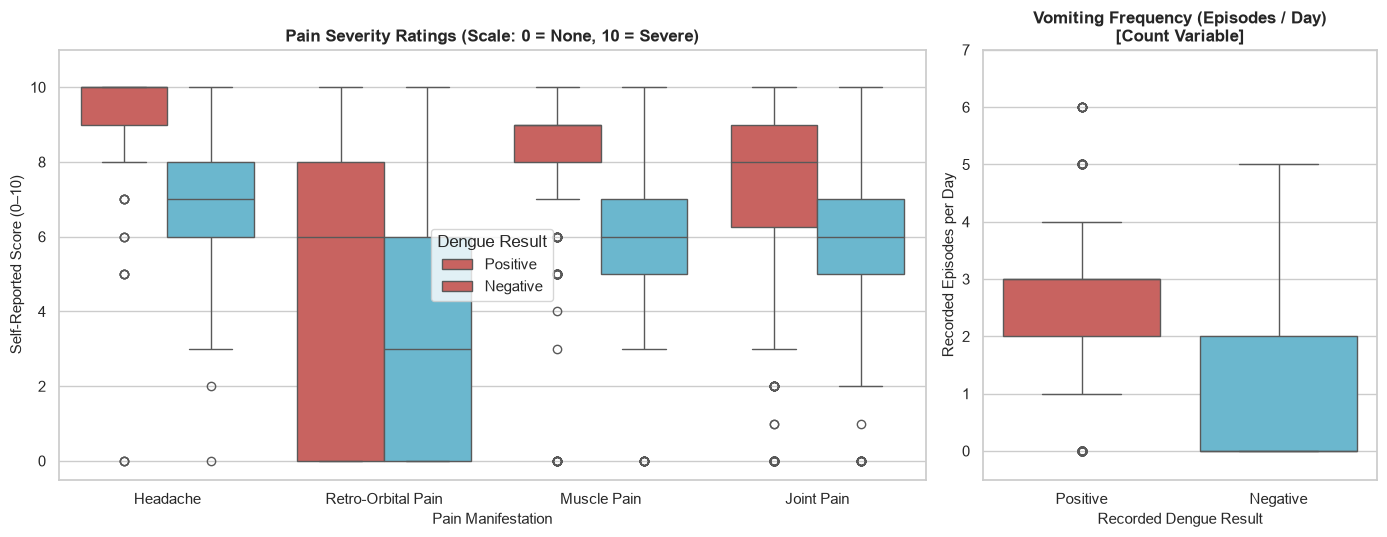

In [33]:
# Visualization for RQ3: Multi-Panel Boxplots Distinguishing Severity Scores from Vomiting Frequency
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [2.2, 1]})

# Subplot 3A: Pain Severity Scores (0 to 10 Scale)
pain_cols = ['headache_severity', 'retro_orbital_pain', 'muscle_pain', 'joint_pain']
df_pain_melted = df_working.melt(
    id_vars=['dengue_result'], 
    value_vars=pain_cols,
    var_name='Symptom', 
    value_name='Severity_Score'
)
df_pain_melted['Symptom'] = df_pain_melted['Symptom'].map({
    'headache_severity': 'Headache',
    'retro_orbital_pain': 'Retro-Orbital Pain',
    'muscle_pain': 'Muscle Pain',
    'joint_pain': 'Joint Pain'
})

sns.boxplot(x='Symptom', y='Severity_Score', hue='dengue_result', data=df_pain_melted, 
            ax=axes[0], palette=['#d9534f', '#5bc0de'])
axes[0].set_title("Pain Severity Ratings (Scale: 0 = None, 10 = Severe)", fontsize=12, weight='bold')
axes[0].set_xlabel("Pain Manifestation", fontsize=11)
axes[0].set_ylabel("Self-Reported Score (0–10)", fontsize=11)
axes[0].set_ylim(-0.5, 11)
axes[0].legend(title='Dengue Result', labels=['Positive', 'Negative'])

# Subplot 3B: Vomiting Frequency (Count Variable)
sns.boxplot(x='dengue_result', y='vomiting_per_day', data=df_working, 
            ax=axes[1], palette=['#d9534f', '#5bc0de'])
axes[1].set_title("Vomiting Frequency (Episodes / Day)\n[Count Variable]", fontsize=12, weight='bold')
axes[1].set_xlabel("Recorded Dengue Result", fontsize=11)
axes[1].set_ylabel("Recorded Episodes per Day", fontsize=11)
axes[1].set_xticklabels(['Positive', 'Negative'])
axes[1].set_ylim(-0.5, 7)

plt.tight_layout()
plt.show()

#### Interpretation of RQ3 Findings
1. **Pain Severity Scores (0–10 Scale):**
   - **Headache:** Higher median severity among dengue-positive participants (**10.0**, IQR: 1.0, Mean: 9.41) compared to dengue-negative participants (**7.0**, IQR: 2.0, Mean: 7.04).
   - **Muscle Pain:** Higher median severity among dengue-positive participants (**9.0**, IQR: 1.0, Mean: 8.30) compared to dengue-negative participants (**6.0**, IQR: 2.0, Mean: 6.03).
   - **Joint Pain:** Higher median severity among dengue-positive participants (**8.0**, IQR: 2.75, Mean: 7.46) compared to dengue-negative participants (**6.0**, IQR: 2.0, Mean: 5.97).
   - **Retro-Orbital Pain:** Higher median severity among dengue-positive participants (**6.0**, IQR: 8.0, Mean: 4.94) compared to dengue-negative participants (**3.0**, IQR: 6.0, Mean: 3.12).
2. **Vomiting Frequency (Count Variable):**
   - **Dengue-Positive:** Median vomiting frequency was **3.0 episodes/day** (IQR: 1.0, Mean: 2.56 episodes/day).
   - **Dengue-Negative:** Median vomiting frequency was **0.0 episodes/day** (IQR: 2.0, Mean: 1.04 episodes/day).
   - *Descriptive summary:* Dengue-positive participants had higher median scores for all four recorded pain measures in this dataset. They also reported a higher frequency of daily vomiting episodes.

### 18.4 RQ4: Exposure and Environmental Factors

> **Research Question 4:**  
> *How are household dengue exposure, stagnant water, area type, and previous dengue infection associated with dengue test positivity?*

#### What are we checking?
We examine four environmental, household, and historical exposure variables:
1. `household_dengue_exposure_14d`: Reported household dengue infection within the previous 14 days.
2. `stagnant_water`: Presence of standing/stagnant water near residence.
3. `area_type`: Residential area classification (Urban, Semi-urban, Rural).
4. `ever_dengue`: Self-reported history of past dengue infection.

#### Why are we checking it?
We examine whether reported household and environmental factors differ in their observed dengue-positive proportions.

In [34]:
# RQ4: Calculate cross-tabulations and positive proportions for all exposure variables
exposure_variables = [
    ('household_dengue_exposure_14d', 'Household Exposure (Past 14 Days)'),
    ('stagnant_water', 'Stagnant Water Nearby'),
    ('area_type', 'Residential Area Type'),
    ('ever_dengue', 'Prior Dengue Infection')
]

rq4_tables = []
for var_col, var_title in exposure_variables:
    # Compute counts and row percentages
    crosstab_counts = pd.crosstab(df_working[var_col], df_working['dengue_result'])
    crosstab_pcts = pd.crosstab(df_working[var_col], df_working['dengue_result'], normalize='index') * 100
    
    # Format a concise table
    summary_tbl = pd.DataFrame({
        'Category': crosstab_counts.index,
        'Exposure Factor': var_title,
        'Total Participants': crosstab_counts.sum(axis=1).values,
        'Dengue Positive (N)': crosstab_counts['Dengue Positive (ডেঙ্গু পজিটিভ)'].values,
        'Dengue Positive (%)': crosstab_pcts['Dengue Positive (ডেঙ্গু পজিটিভ)'].round(2).values,
        'Dengue Negative (N)': crosstab_counts['Dengue Negative (ডেঙ্গু নেগেটিভ)'].values,
        'Dengue Negative (%)': crosstab_pcts['Dengue Negative (ডেঙ্গু নেগেটিভ)'].round(2).values
    })
    rq4_tables.append(summary_tbl)

df_rq4_all = pd.concat(rq4_tables, ignore_index=True)
print("--- EXPOSURE AND ENVIRONMENTAL FACTORS BY DENGUE TEST OUTCOME ---")
df_rq4_all[['Exposure Factor', 'Category', 'Total Participants', 'Dengue Positive (N)', 'Dengue Positive (%)', 'Dengue Negative (%)']]

--- EXPOSURE AND ENVIRONMENTAL FACTORS BY DENGUE TEST OUTCOME ---


,Exposure Factor,Category,Total Participants,Dengue Positive (N),Dengue Positive (%),Dengue Negative (%)
0,Household Exposure (Past 14 Days),No (না),764,451,59.03,40.97
1,Household Exposure (Past 14 Days),Not sure (নিশ্চিত নই),7,5,71.43,28.57
2,Household Exposure (Past 14 Days),Yes (হ্যাঁ),247,174,70.45,29.55
3,Stagnant Water Nearby,No (না),173,89,51.45,48.55
4,Stagnant Water Nearby,Not sure (নিশ্চিত নই),98,70,71.43,28.57
5,Stagnant Water Nearby,Yes (হ্যাঁ),747,471,63.05,36.95
6,Residential Area Type,City Corporation / Urban Area (সিটি কর্পোরেশন ...,837,526,62.84,37.16
7,Residential Area Type,Municipality / Semi-urban Area (পৌরসভা / আধা-শ...,96,53,55.21,44.79
8,Residential Area Type,Village / Rural Area (গ্রাম / পল্লি অঞ্চল),85,51,60.00,40.00
9,Prior Dengue Infection,No (না),954,585,61.32,38.68


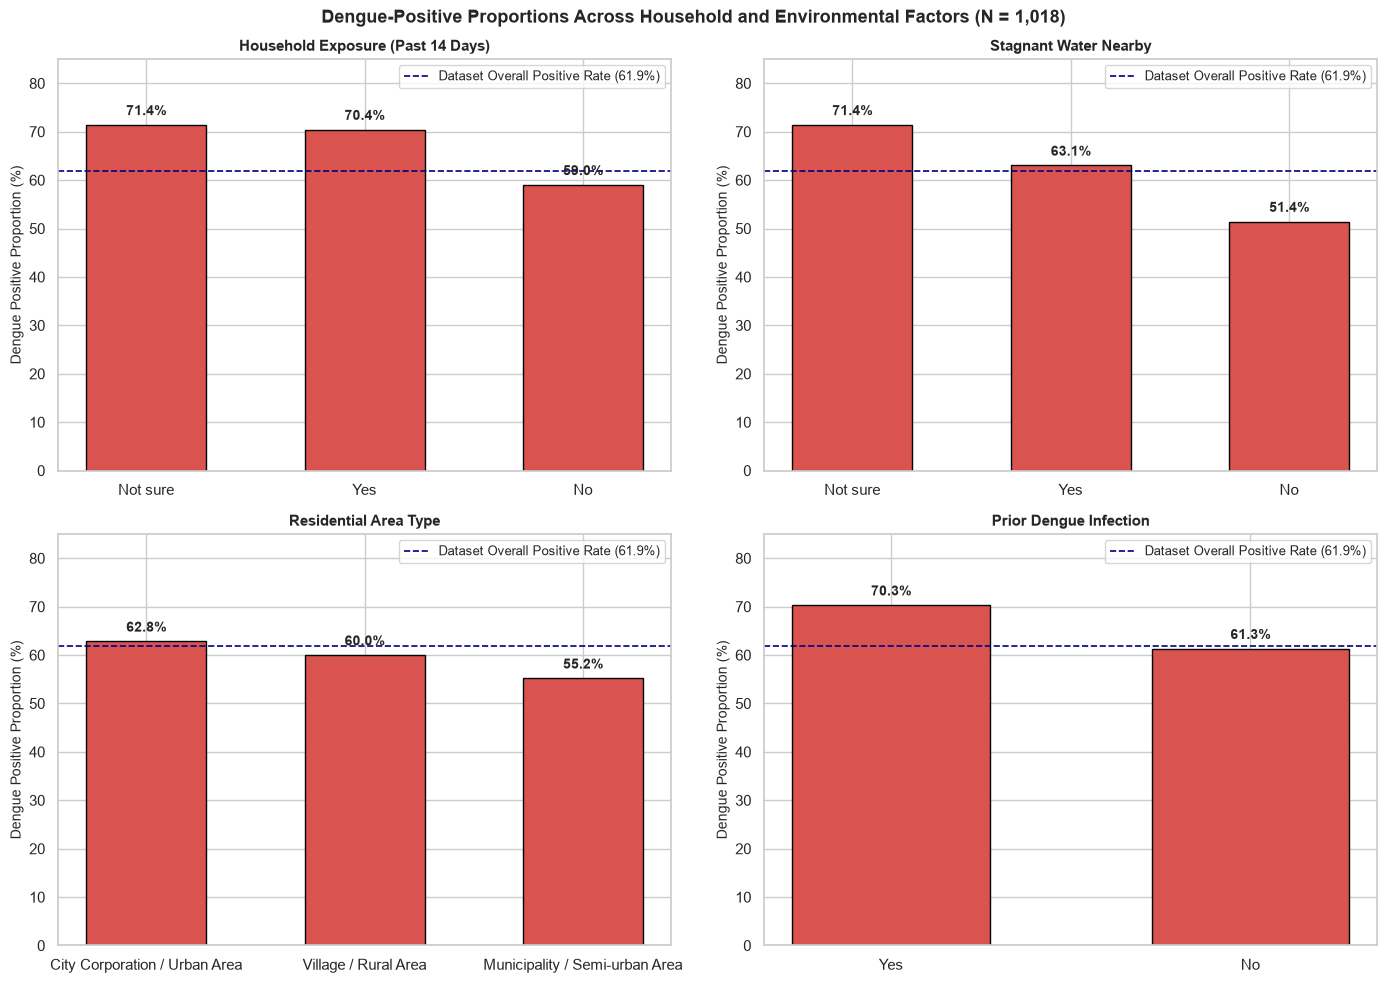

In [35]:
# Visualization for RQ4: Multi-Panel Grouped Bar Chart of Positive Proportions Across Exposure Factors
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for idx, (var_col, var_title) in enumerate(exposure_variables):
    ax = axes[idx // 2, idx % 2]
    
    # Compute percentage positive
    ct_pct = pd.crosstab(df_working[var_col], df_working['dengue_result'], normalize='index') * 100
    pos_rates = ct_pct['Dengue Positive (ডেঙ্গু পজিটিভ)'].sort_values(ascending=False)
    
    # Clean up long bilingual category labels for clean display
    short_labels = [label.split('(')[0].strip() for label in pos_rates.index]
    
    bars = ax.bar(short_labels, pos_rates.values, color='#d9534f', edgecolor='black', width=0.55)
    ax.axhline(61.89, color='navy', linestyle='--', linewidth=1.2, label='Dataset Overall Positive Rate (61.9%)')
    
    ax.set_title(f"{var_title}", fontsize=11, weight='bold')
    ax.set_ylabel("Dengue Positive Proportion (%)", fontsize=10)
    ax.set_ylim(0, 85)
    ax.legend(loc='upper right', fontsize=9)
    
    # Annotate bar values
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 2, f"{h:.1f}%", ha='center', fontsize=10, weight='bold')

plt.suptitle("Dengue-Positive Proportions Across Household and Environmental Factors (N = 1,018)", fontsize=13, weight='bold')
plt.tight_layout()
plt.show()

#### Interpretation of RQ4 Findings
1. **Household Exposure (Past 14 Days):**
   - Participants reporting household dengue exposure within the previous 14 days had a higher positive proportion (**70.45%**, 174/247) compared to those without reported exposure (**59.03%**, 451/764), representing an **11.42 percentage-point difference**.
2. **Stagnant Water Nearby:**
   - Participants reporting stagnant water near their residence had a higher positive proportion (**63.05%**, 471/747) compared to those without stagnant water (**51.45%**, 89/173), an **11.60 percentage-point difference**.
3. **Residential Area Type:**
   - Dengue-positive proportions were fairly consistent across urban/rural zones: City Corporation / Urban Area (**62.84%**, 526/837), Village / Rural Area (**60.00%**, 51/85), and Municipality / Semi-urban Area (**55.21%**, 53/96).
4. **Prior Dengue History:**
   - Participants reporting a previous dengue infection had a higher positive proportion (**70.31%**, 45/64) than those with no prior history (**61.32%**, 585/954), an **8.99 percentage-point difference**.
   - *Non-causal note:* These associations describe patterns among study participants in this dataset. They do not demonstrate direct causation, as unmeasured confounding factors (such as mosquito density and neighborhood topography) were not captured in this survey.

## 19. Preliminary Findings

Based strictly on the calculated results across the 1,018 study participants, we summarize the primary findings:

### RQ1: Fever Characteristics
1. **Fever Duration:** Dengue-positive participants had a slightly higher median recorded fever duration (**7.0 days**, IQR: 3.0, Mean: 6.73) compared to dengue-negative participants (**6.0 days**, IQR: 3.0, Mean: 6.28).
2. **Maximum Temperature:** Within the predefined 99°F–106°F analytical range (N = 1,002), dengue-positive participants had a distinctly higher median recorded temperature (**104.0°F**, IQR: 1.0, Mean: 103.77°F) compared to dengue-negative participants (**102.0°F**, IQR: 1.0, Mean: 101.75°F). The temperature comparison used 1,002 records within the predefined 99°F–106°F analytical range. The remaining 16 temperature entries were excluded only from this specific temperature comparison; they were retained in the underlying dataset.

### RQ2: Early Symptoms Differentials
1. **Largest Positive Differences:** Appetite loss and fatigue/weakness showed the largest observed percentage-point differences between the dengue-positive and dengue-negative groups:
   - Appetite loss showed the largest difference (**+69.31 percentage points**; 99.21% vs. 29.90%).
   - Fatigue/weakness showed the second-largest difference (**+58.70 percentage points**; 99.68% vs. 40.98%).
   - Nausea showed a notable positive difference (**+33.01 percentage points**; 98.73% vs. 65.72%).
2. **Inverted Differences:** Localized gastrointestinal symptoms were reported more frequently among dengue-negative participants:
   - Abdominal pain was present in 56.19% of negative vs. 23.33% of positive participants (**-32.85 percentage points**).
   - Diarrhea was present in 62.63% of negative vs. 40.79% of positive participants (**-21.84 percentage points**).
3. **Skin Rash & Bleeding:** Skin rash showed minimal difference between groups (**-2.34 percentage points**; 21.11% vs. 23.45%), while bleeding was infrequent overall but slightly higher in positive participants (**+4.31 percentage points**; 7.14% vs. 2.84%).

### RQ3: Symptom Severity Scores and Vomiting Frequency
1. **Pain Severity (0–10 Scale):** Dengue-positive participants had higher median scores for all four recorded pain measures in this dataset: headache (**10.0** vs. **7.0**), muscle pain (**9.0** vs. **6.0**), joint pain (**8.0** vs. **6.0**), and retro-orbital pain (**6.0** vs. **3.0**).
2. **Vomiting Frequency (Episodes/Day):** Dengue-positive participants recorded a higher median vomiting frequency (**3.0 episodes/day**, IQR: 1.0) compared to dengue-negative participants (**0.0 episodes/day**, IQR: 2.0).

### RQ4: Exposure and Environmental Associations
1. **Household Exposure:** Reporting a household dengue infection in the previous 14 days was associated with a higher positive proportion (**70.45%** vs. **59.03%** among those without reported exposure).
2. **Stagnant Water:** Living near stagnant water was associated with higher dengue positivity (**63.05%** vs. **51.45%** without stagnant water).
3. **Prior Infection:** Participants reporting a prior dengue infection had a higher positivity proportion (**70.31%** vs. **61.32%**).

## 20. Limitations

To maintain academic rigor, the following methodological and dataset limitations are acknowledged:
1. **Survey-Based Data:** The dataset is composed of self-reported survey responses, which are inherently subject to recall bias, subjective pain interpretation, and reporting differences.
2. **Unverified Clinical Outcomes:** Recorded dengue test results were not independently verified against primary laboratory reports or hospital patient charts according to available dataset documentation.
3. **Unspecified Test Modality & Timing:** The dataset does not specify the diagnostic test modality (e.g., NS1 antigen, IgM/IgG ELISA, or RT-PCR) nor the exact timing of testing relative to fever onset.
4. **Non-Representative Sample:** The 1,018 participants represent individuals selected for survey and testing; this cohort should not be interpreted as a nationally representative random sample of Bangladesh.
5. **Temperature Data Anomalies:** Sixteen temperature entries contained anomalies (12 missing, 1 text string `'Munshiganj'`, 1 implausible `'8°F'`, and 2 unusually high `'107°F'`), necessitating an analytical filtering decision (99°F–106°F) for descriptive temperature comparisons.
6. **Derived District Standardization:** District entries exhibited whitespace fragmentation and minor spelling variants, requiring documented derived standardizations on the working copy.
7. **Cross-Sectional & Non-Causal Nature:** Observed statistical associations describe patterns within this specific dataset and must not be interpreted as establishing clinical or biological causality.

## 21. Possible Next Steps

For subsequent research phases, the following next steps are recommended:
1. **Verify Anomalous Entries:** Follow up with primary dataset creators to resolve the 16 anomalous temperature entries and ascertain primary survey documentation.
2. **Conduct Inferential Testing:** Apply formal non-parametric statistical hypothesis tests (e.g., Mann-Whitney U for ordinal scores, Chi-squared tests for proportions) to determine statistical significance.
3. **Subgroup & Stratification Analysis:** Examine whether symptom differentials and exposure patterns remain consistent across demographic subgroups (e.g., age bands, gender, urban vs. rural settings).
4. **Independent Dataset Validation:** Validate observed symptom patterns using external clinical cohorts from other Bangladeshi hospitals or subsequent dengue epidemic seasons.

## 22. Final Project Status

**Course:** BDS3106 — Programming for Data Science  
**Notebook Version:** v3  
**Status:** Version v3 completed.

### Summary of Completed Work in Version v3:
- Documented official Mendeley Data source metadata, DOI, public repository access link, and CC BY 4.0 licence.
- Full dataset audit and data dictionary completed across all 1,018 rows and 23 variables.
- Cryptographic raw-data integrity verified via SHA-256 baseline matching.
- Derived district standardization completed (296 whitespace + 4 spelling/casing = 300 records standardized into 18 categories) while preserving `district_original`.
- Strict non-imputation and non-deletion rules maintained for all 16 problematic temperature entries and both zero-fever participants.
- Exploratory Data Analysis executed for RQ1, RQ2, RQ3, and RQ4 with student-friendly, accessible visualizations.
- Refined vomiting classification to a self-reported frequency/count variable and eliminated clinical profiling and causal phrasing.
- Preliminary findings, limitations, and future research steps fully documented.

---
**Version v3 completed.**